# Horse Training Data Analysis and Visualization

This Jupyter Notebook focuses on analyzing and visualizing horse training data using metrics derived from a JSON dataset. The primary objectives include:

1. **Data Processing**:
   - Load and parse a JSON file containing horse training data.
   - Flatten nested structures into a tabular format using pandas for easier analysis.
   - Sort and clean the data for visualization.

2. **Visualization of Metrics**:
   - **Trot Distance Load**: Visualize the daily trot distance load for each horse over time, both individually and in subplots for all horses.
   - **ACWR Metrics**: Analyze and plot Acute:Chronic Workload Ratio (ACWR) metrics for:
     - Distance
     - Duration
     - iTrimp (internal training load)
   - Highlight risk categories (e.g., undertraining, optimal, overreaching, overtraining) based on ACWR thresholds.

3. **Combined ACWR Comparison**:
   - Compare multiple ACWR metrics (Distance, Duration, iTrimp) for each horse in a single plot.

The notebook uses Python libraries such as `pandas`, `matplotlib`, and `seaborn` for data manipulation and visualization. It provides insights into horse training performance and workload management, helping identify trends and potential risks.

In [7]:
import json
import pandas as pd

# Use relative path to the file
path_horse_readiness_json = "datasets/Horse_Readiness_FULLY_FIXED.json"


with open(path_horse_readiness_json, "r", encoding="utf-8") as f:
    data = json.load(f)

records = []

for entry in data:
    horse_id = entry.get("HorseID", "unknown")
    acwr = entry.get("ACWR", {})

    for date, metrics in acwr.items():
        flat_record = {"HorseID": horse_id, "Date": date}

        for category, submetrics in metrics.items():
            for subname, values in submetrics.items():
                for k, v in values.items():
                    column_name = f"{category}_{subname}_{k}"
                    flat_record[column_name] = float(v) if v.replace('.', '', 1).isdigit() else v

        records.append(flat_record)

df = pd.DataFrame(records)

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df.sort_values(["HorseID", "Date"], inplace=True)

display(df.sample(10))

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
733,257,2024-11-07,5.97,40.25,37.12,29.68,1.25,5.43,18.92,15.67,...,0.00,4.72,4.76,4.59,1.04,0.0,0.00,0.02,0.04,0.50
471,257,2024-02-18,5.97,39.49,31.05,26.37,1.18,1.63,15.90,12.95,...,0.00,0.72,1.34,2.55,0.53,0.0,0.18,0.09,0.09,1.00
1308,311,2023-09-23,0.89,26.21,24.88,14.69,1.69,0.67,11.16,9.59,...,0.00,33.95,18.67,6.74,2.77,0.0,0.00,0.32,0.51,0.63
14,257,2022-11-18,8.05,32.66,32.17,18.61,1.73,1.70,10.98,8.79,...,4.85,10.58,12.46,7.87,1.58,0.0,0.00,0.00,0.00,0.00
1647,311,2024-08-26,0.00,14.80,11.65,19.53,0.60,0.00,5.11,4.04,...,0.00,4.38,3.36,4.66,0.72,0.0,0.00,0.02,0.07,0.29
2114,483,2024-08-17,0.00,3.12,4.91,5.07,0.97,0.00,3.09,2.73,...,0.00,0.00,0.17,0.18,0.94,0.0,0.00,0.02,0.07,0.29
2215,483,2024-11-26,2.44,5.07,5.16,7.67,0.67,1.34,2.52,2.89,...,0.00,0.00,0.02,0.07,0.29,0.0,0.00,0.02,0.07,0.29
2464,602,2025-02-08,0.00,37.19,32.19,29.85,1.08,0.00,11.21,9.02,...,0.00,6.65,3.67,2.11,1.74,0.0,25.33,19.38,23.71,0.82
2063,483,2024-06-27,0.00,10.73,15.51,13.68,1.13,0.00,6.63,8.89,...,0.00,0.00,0.02,0.17,0.12,0.0,0.00,0.02,0.07,0.29
599,257,2024-06-26,6.33,36.55,35.66,25.03,1.42,3.22,17.48,16.60,...,0.00,5.64,7.70,5.20,1.48,0.0,0.00,0.02,0.04,0.50


## Trost distance load over time per horse
One Chart per Horse (Sequential Display)

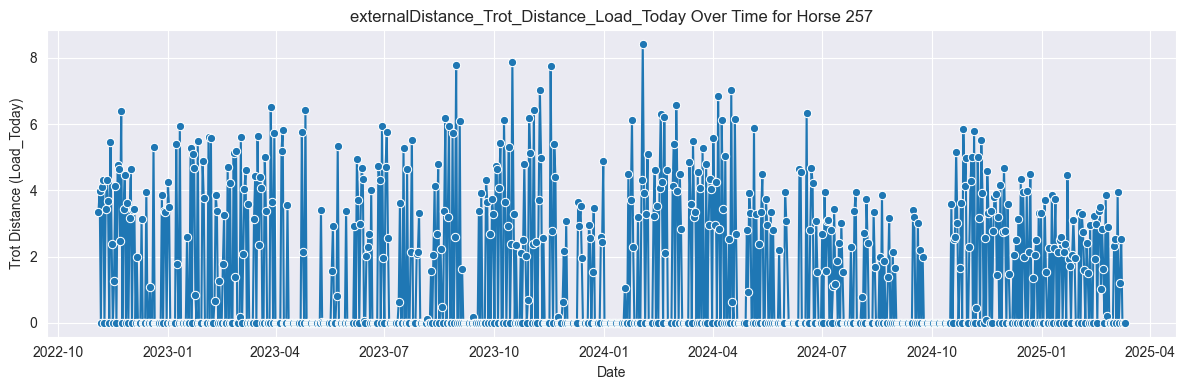

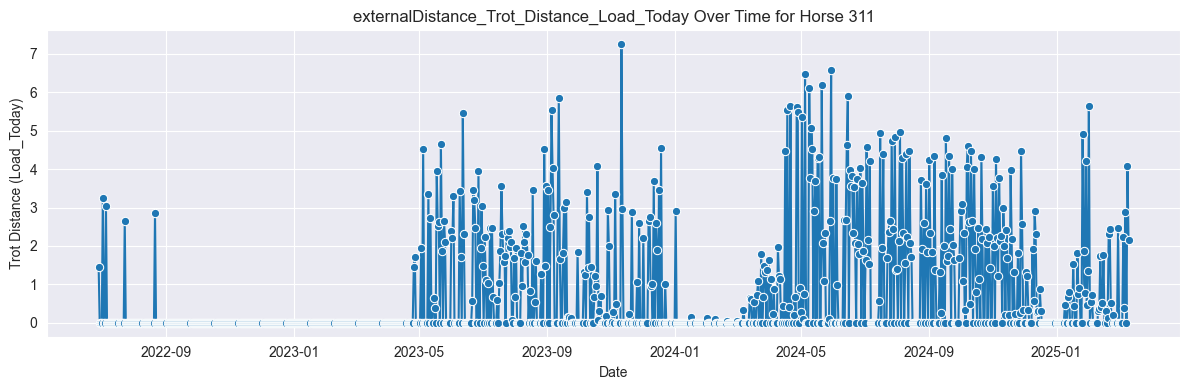

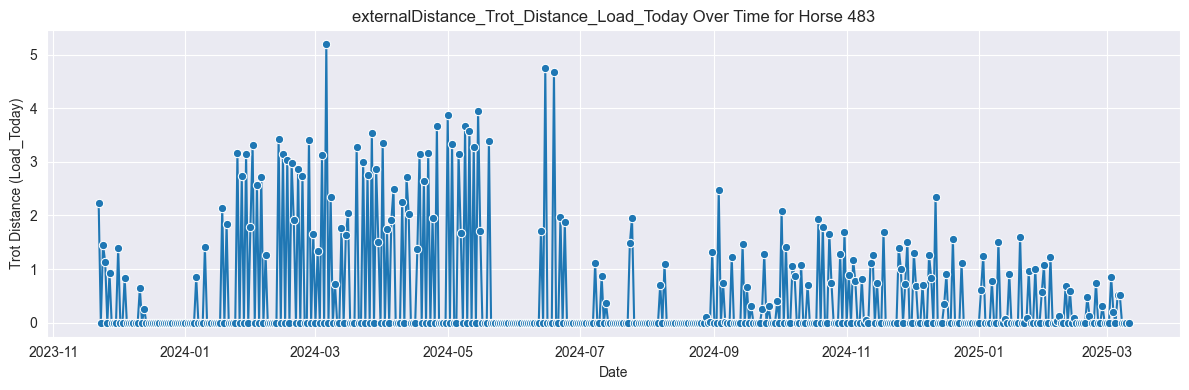

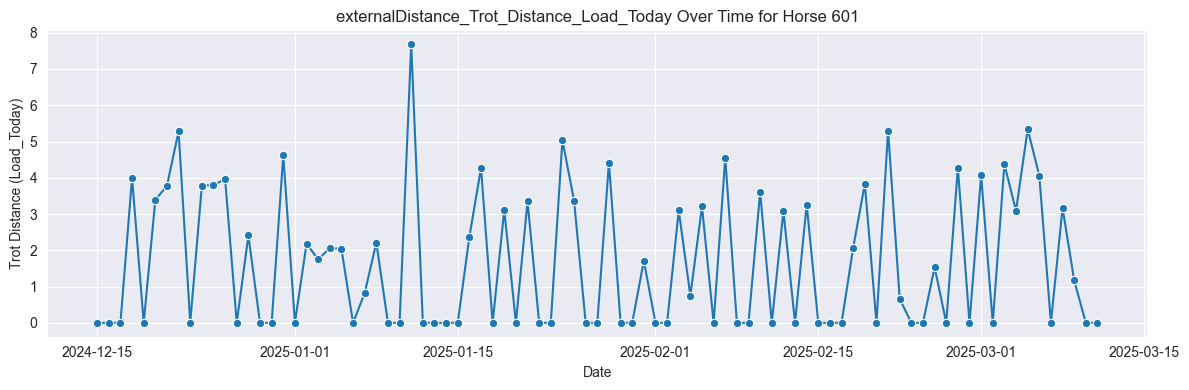

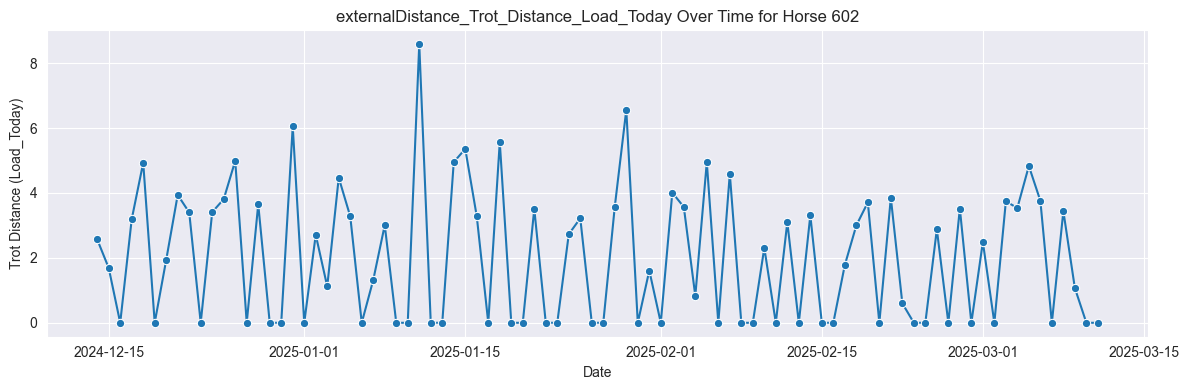

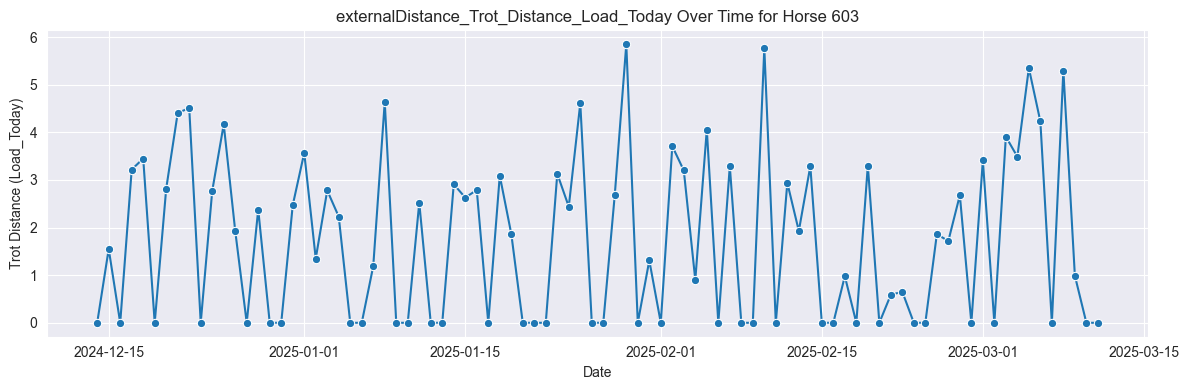

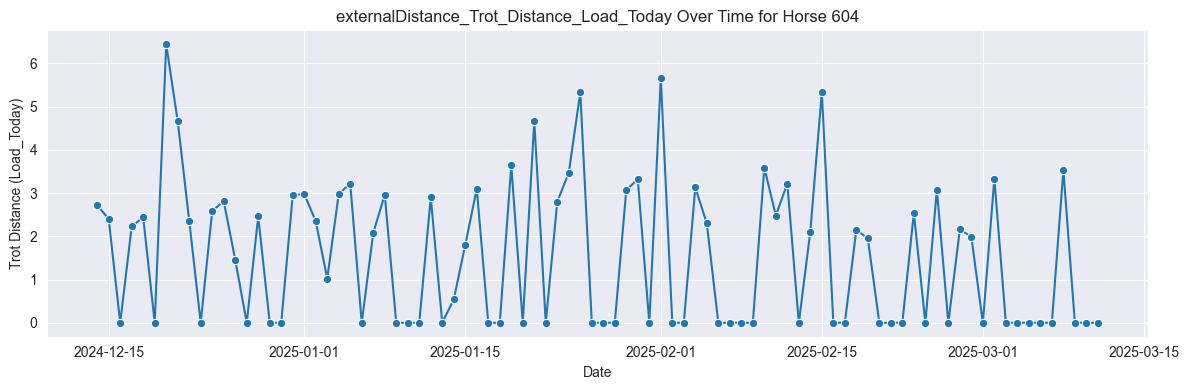

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set metric to visualize
metric = 'externalDistance_Trot_Distance_Load_Today'

# Filter and convert values
df_filtered = df[['HorseID', 'Date', metric]].dropna()
df_filtered[metric] = df_filtered[metric].astype(float)

# Get unique horses
unique_horses = df_filtered['HorseID'].unique()

# Plot one figure per horse
for horse_id in unique_horses:
    horse_df = df_filtered[df_filtered['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=metric, marker="o")
    plt.title(f'{metric} Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('Trot Distance (Load_Today)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Each plot corresponds to a single horse's daily performance in the Trot way of moving, specifically:
Metric Plotted: externalDistance_Trot_Distance_Load_Today

X-axis: Dates (from training logs)

Y-axis: Distance covered in trot on that day (in whatever unit the dataset uses, likely kilometers)

All Horses in Subplots (Small Multiples)

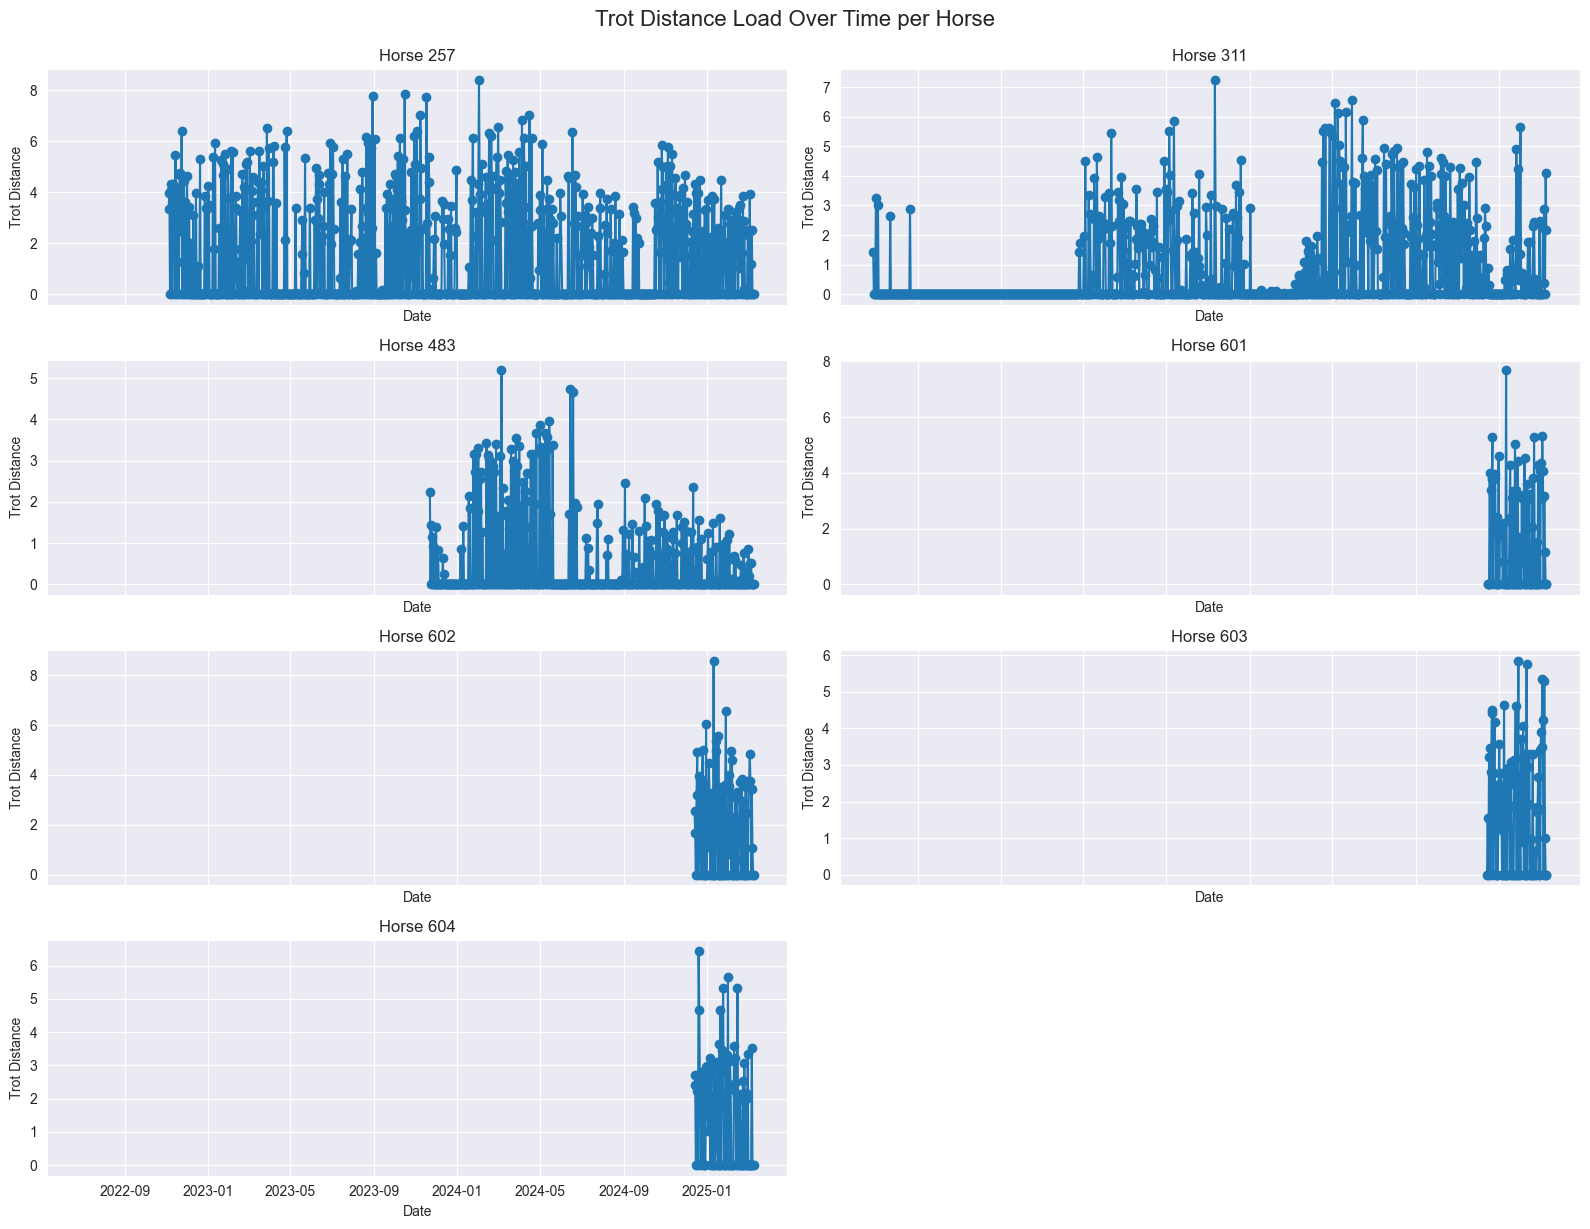

In [9]:
import matplotlib.pyplot as plt

# Filter again to be safe
df_filtered = df[['HorseID', 'Date', metric]].dropna()
df_filtered[metric] = df_filtered[metric].astype(float)

# Get horses and layout
unique_horses = df_filtered['HorseID'].unique()
num_horses = len(unique_horses)
cols = 2  # adjust for layout
rows = (num_horses + 1) // cols

# Create subplots
fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3), sharex=True)
axes = axes.flatten()

for i, horse_id in enumerate(unique_horses):
    horse_df = df_filtered[df_filtered['HorseID'] == horse_id]
    axes[i].plot(horse_df['Date'], horse_df[metric], marker='o', linestyle='-')
    axes[i].set_title(f'Horse {horse_id}')
    axes[i].set_ylabel('Trot Distance')
    axes[i].set_xlabel('Date')
    axes[i].grid(True)

# Hide unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle('Trot Distance Load Over Time per Horse', fontsize=16, y=1.02)
plt.show()


# ACWR Plots

## Plotting ACWR metrics over time
### 1. Distance
What Does externalDistance_Distance_ACWR Represent?

It tells you how much distance a horse covered this week compared to the average it covered over past weeks.

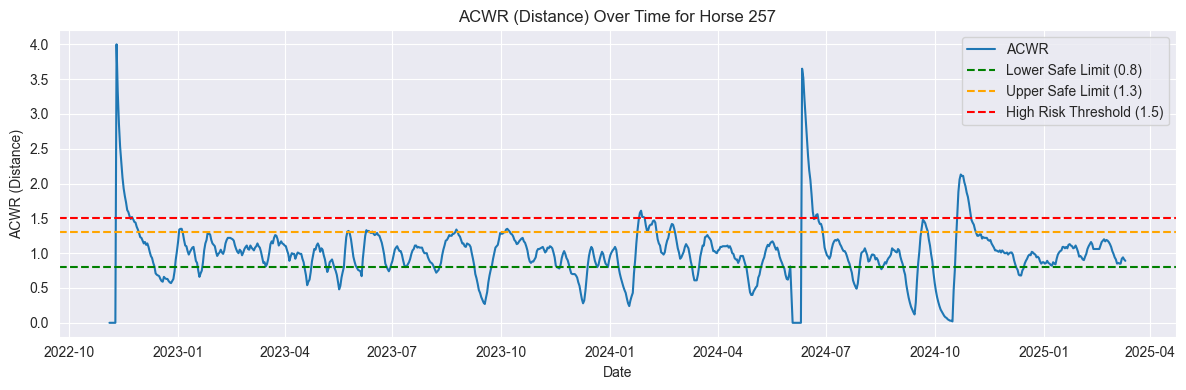

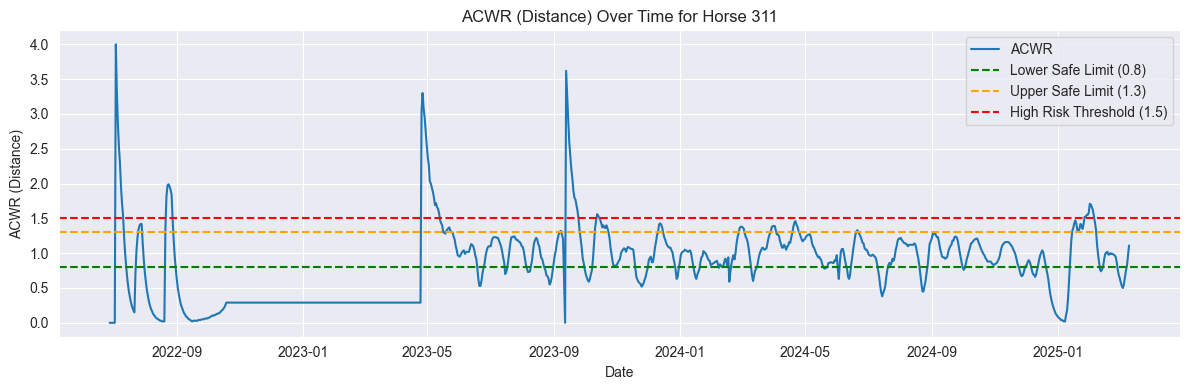

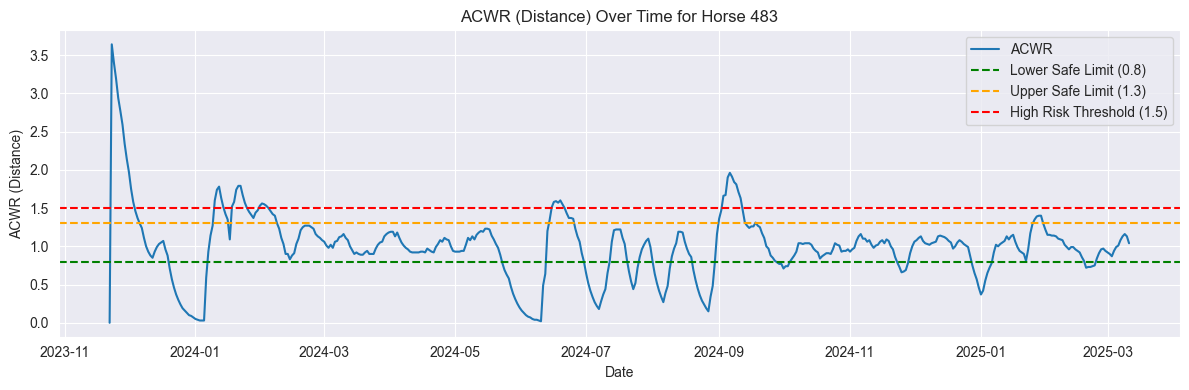

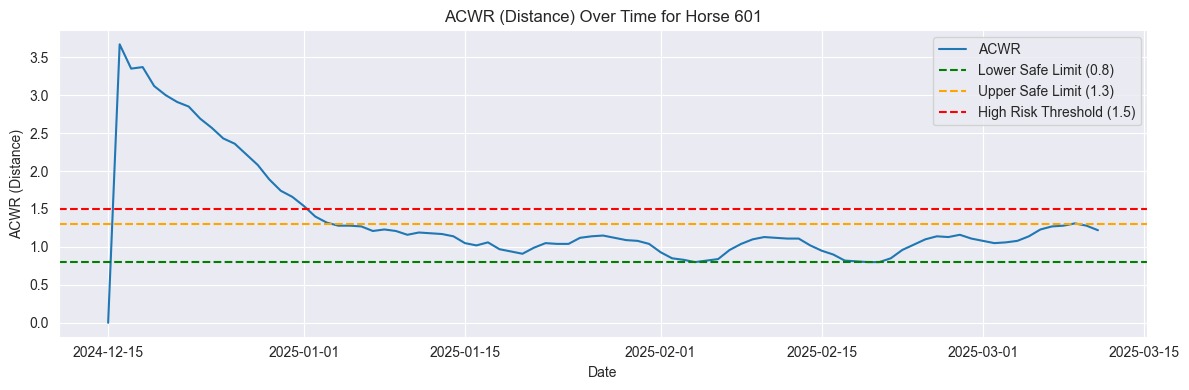

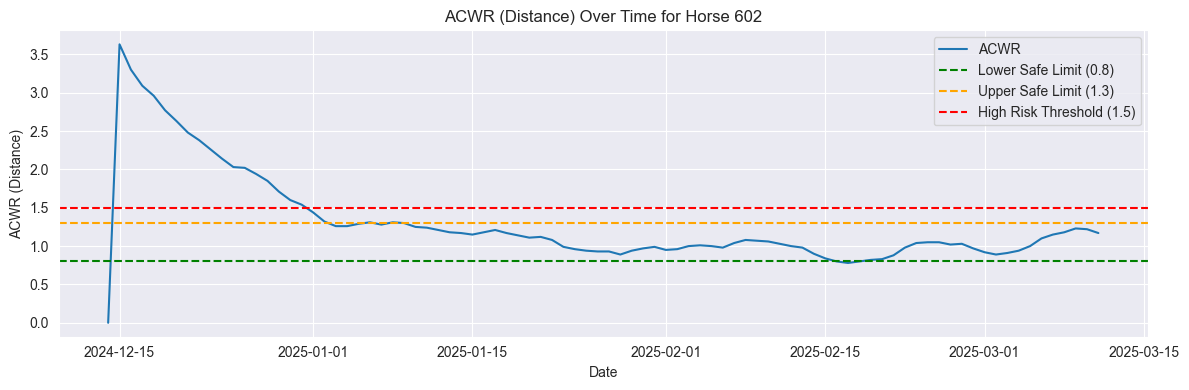

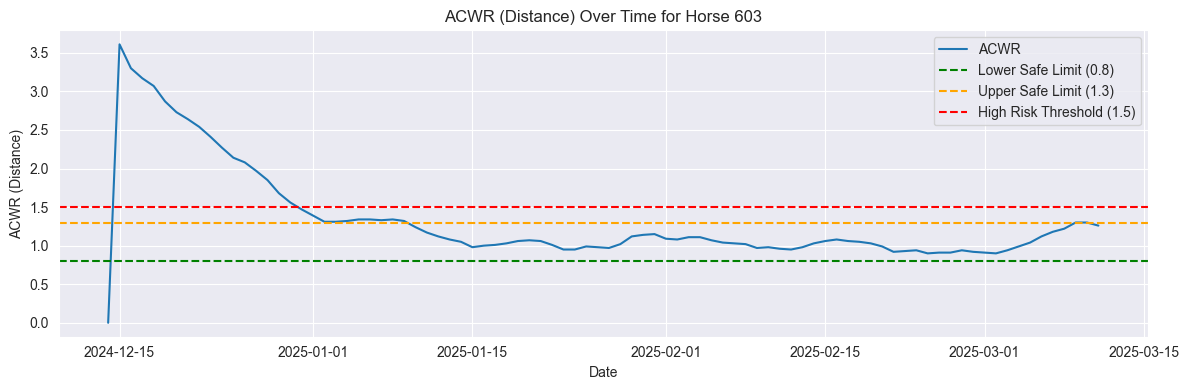

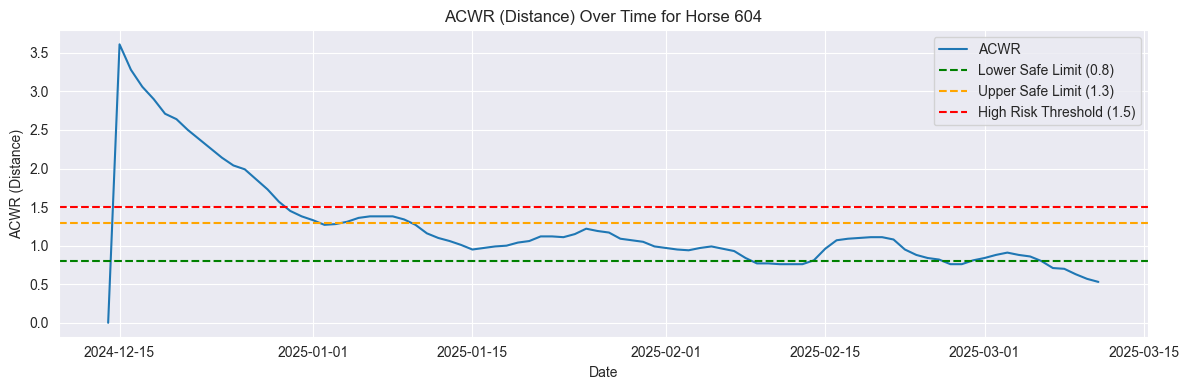

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the ACWR metric column
acwr_col = 'externalDistance_Distance_ACWR'

# Filter and clean data
df_acwr = df[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: create ACWR risk category
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Get list of horses
horses = df_acwr['HorseID'].unique()

# Plot ACWR over time for each horse
for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # Threshold lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    # Formatting
    plt.title(f'ACWR (Distance) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (Distance)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### 2. Duration
What Does externalDuration_Duration_ACWR Represent?

This metric tracks how long a horse trains (in minutes or hours) and compares recent weekly training time to long-term average training time.

ACWR (Duration) = This week's total training time / Average weekly training time over previous weeks

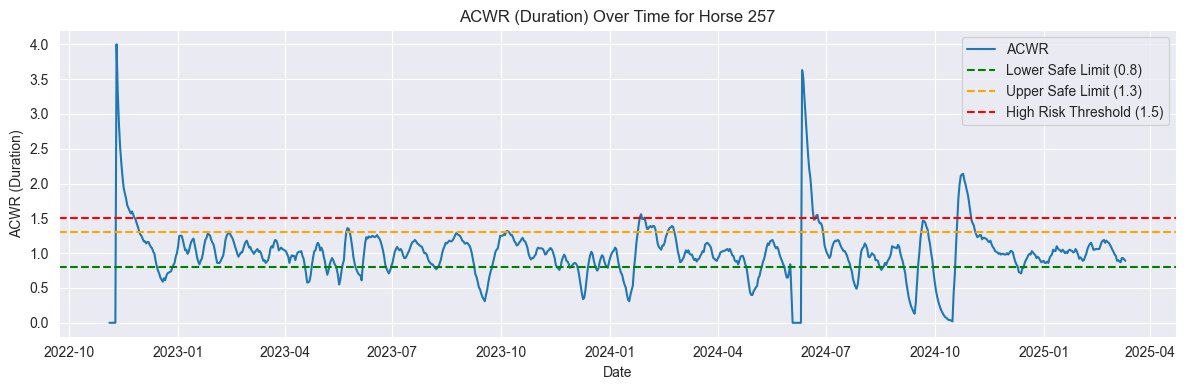

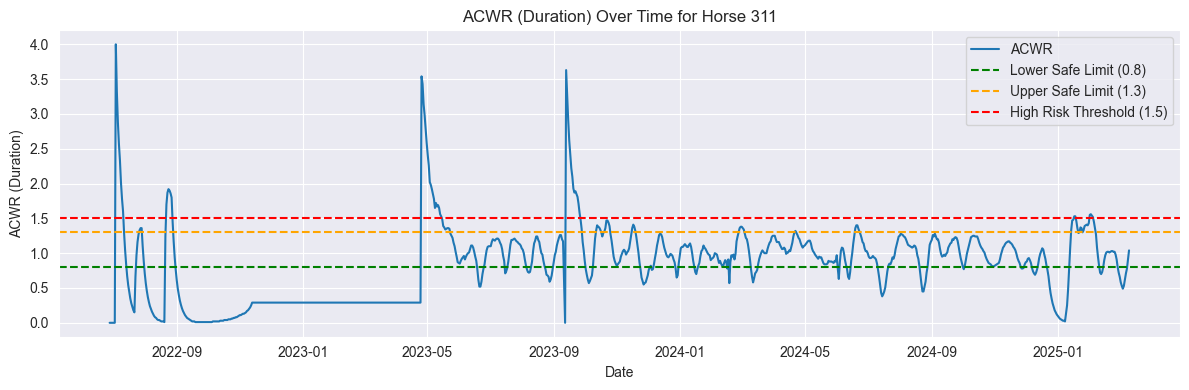

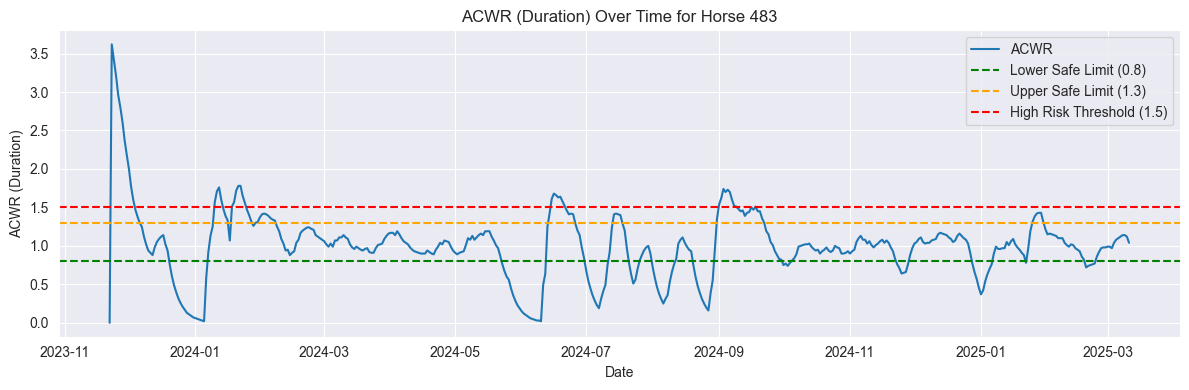

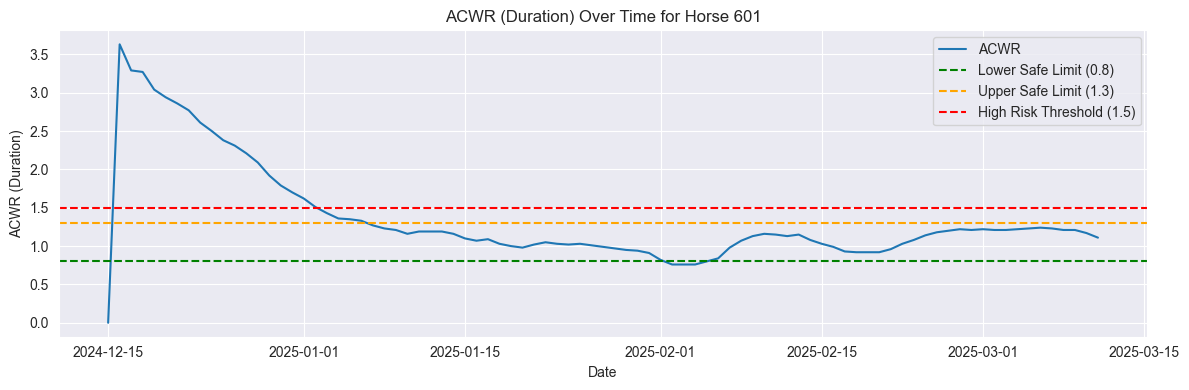

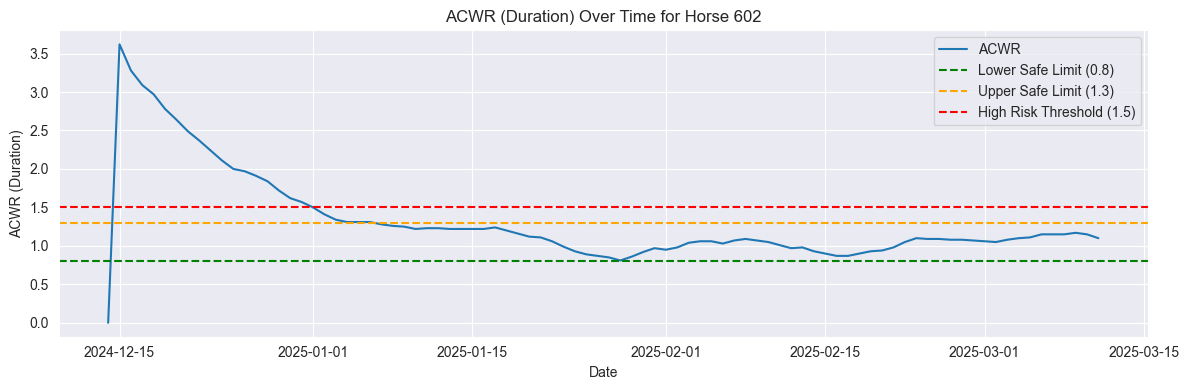

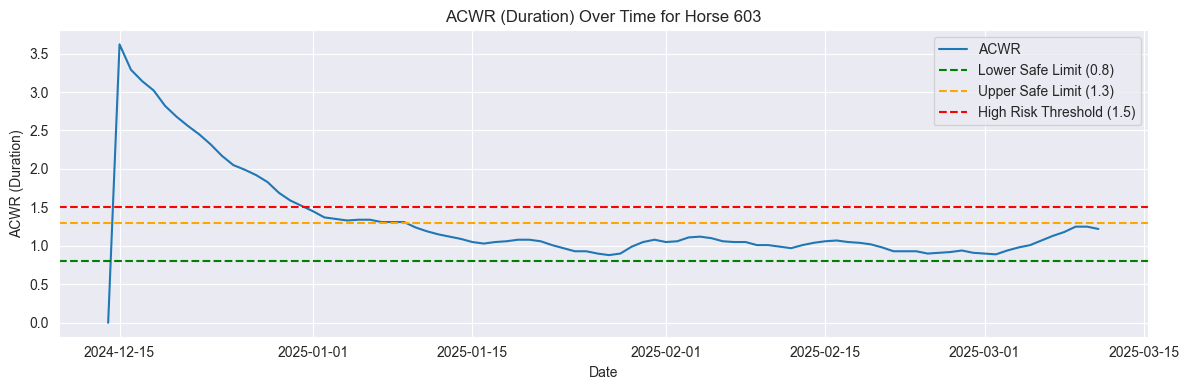

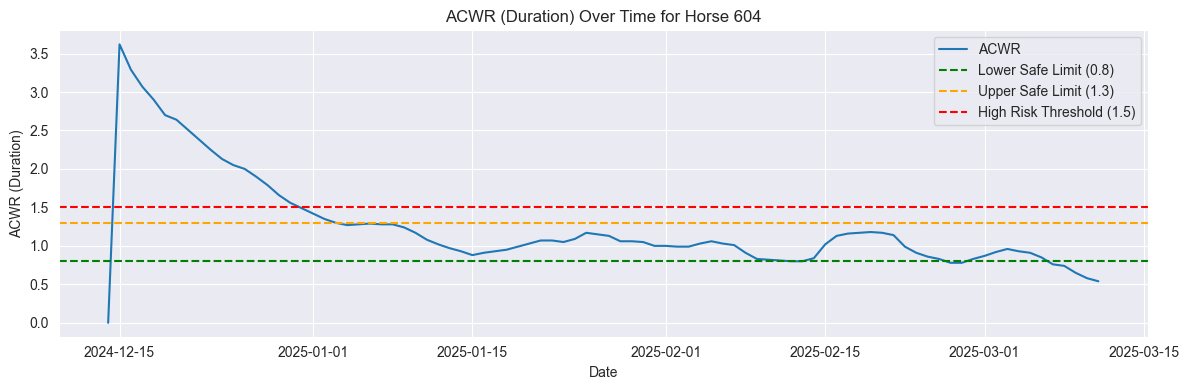

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the ACWR duration metric
acwr_col = 'externalDuration_Duration_ACWR'

# Filter and clean data
df_acwr = df[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: categorize risk
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # Threshold lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (Duration) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (Duration)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### 3. iTrimp
What Does eiTrimp_overall_ACWR Represent?

iTRIMP = individualized Training Impulse

iTRIMP ACWR compares the recent week’s internal load to the horse’s chronic internal load average

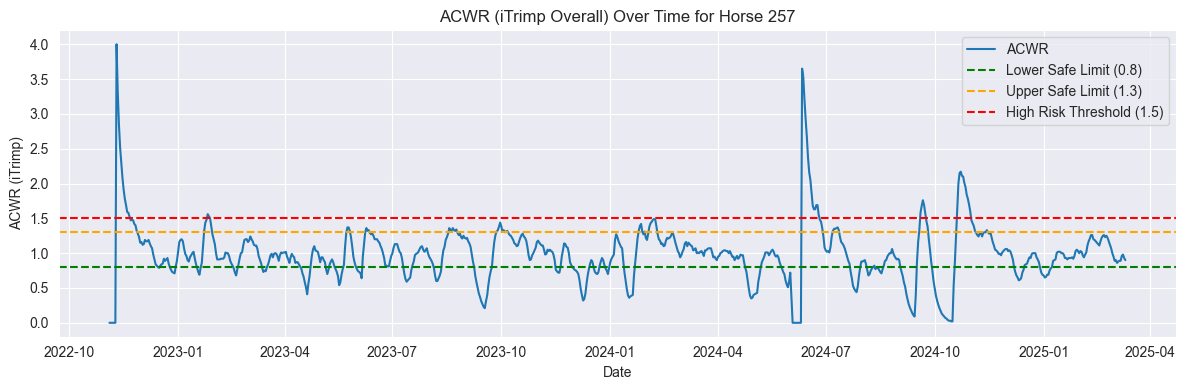

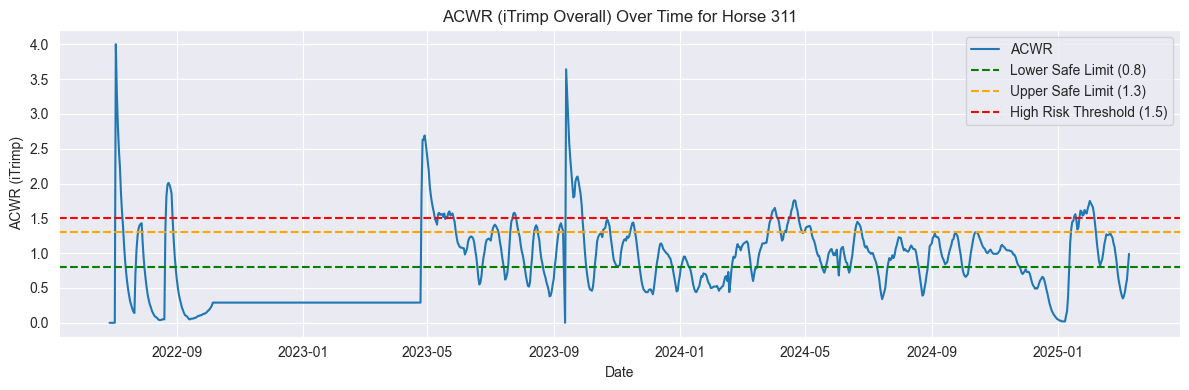

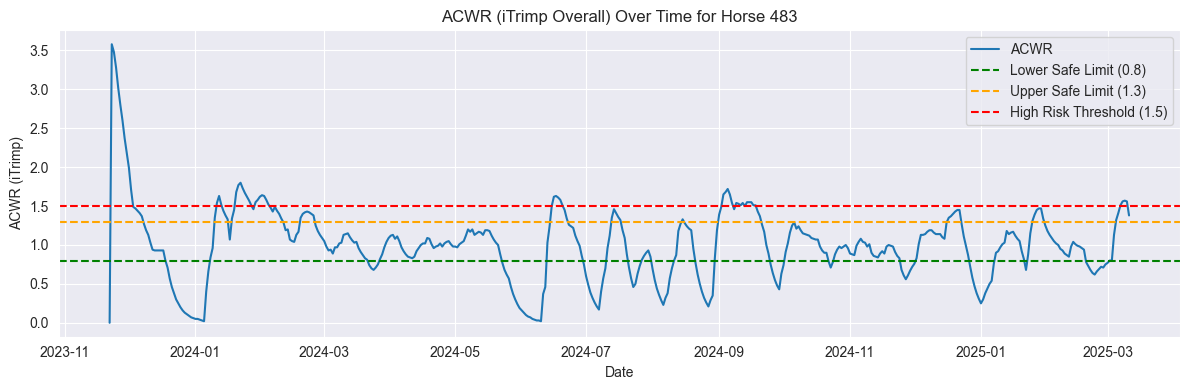

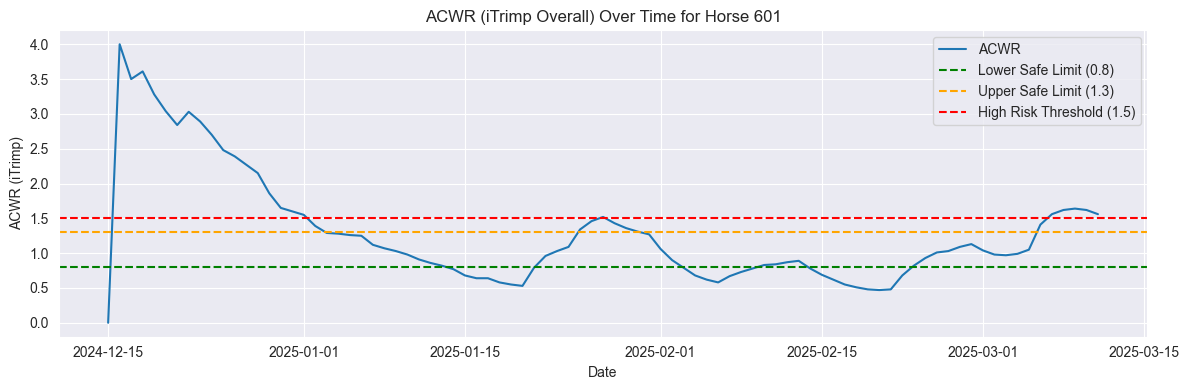

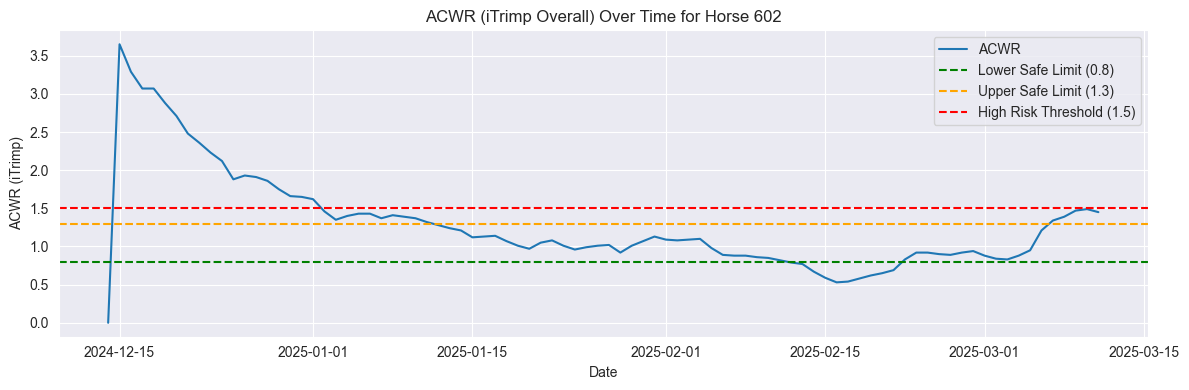

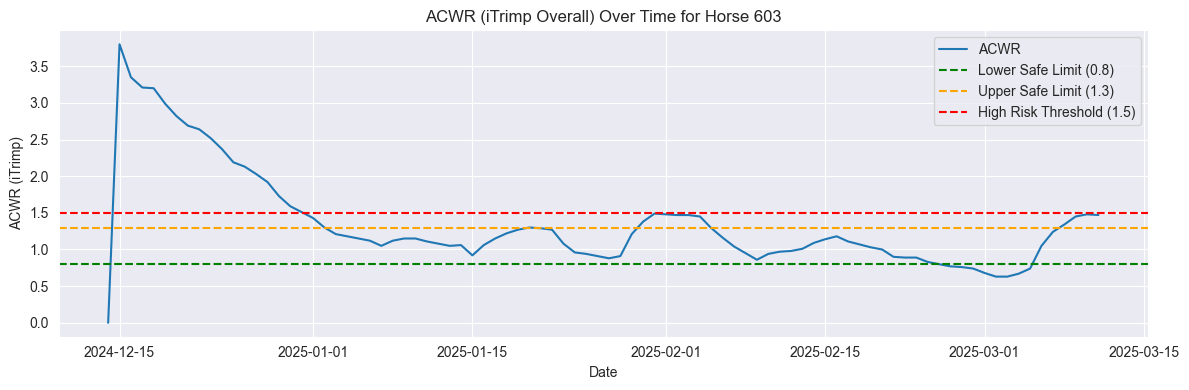

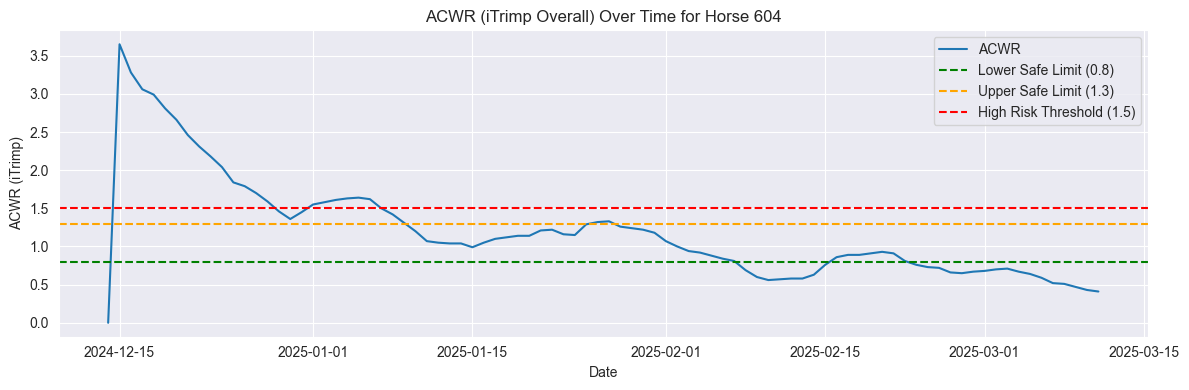

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ACWR metric for internal training load
acwr_col = 'iTrimp_overall_ACWR'

# Filter and clean
df_acwr = df[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: tag risk levels
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # ACWR safe zone lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (iTrimp Overall) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (iTrimp)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Combined ACWR Comparison Plot per Horse

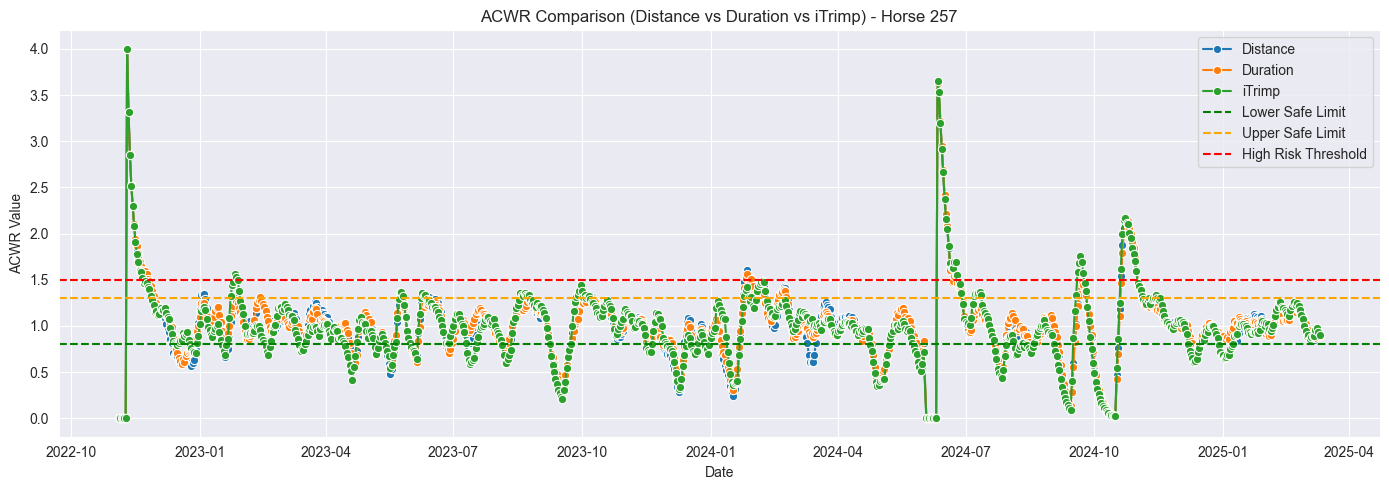

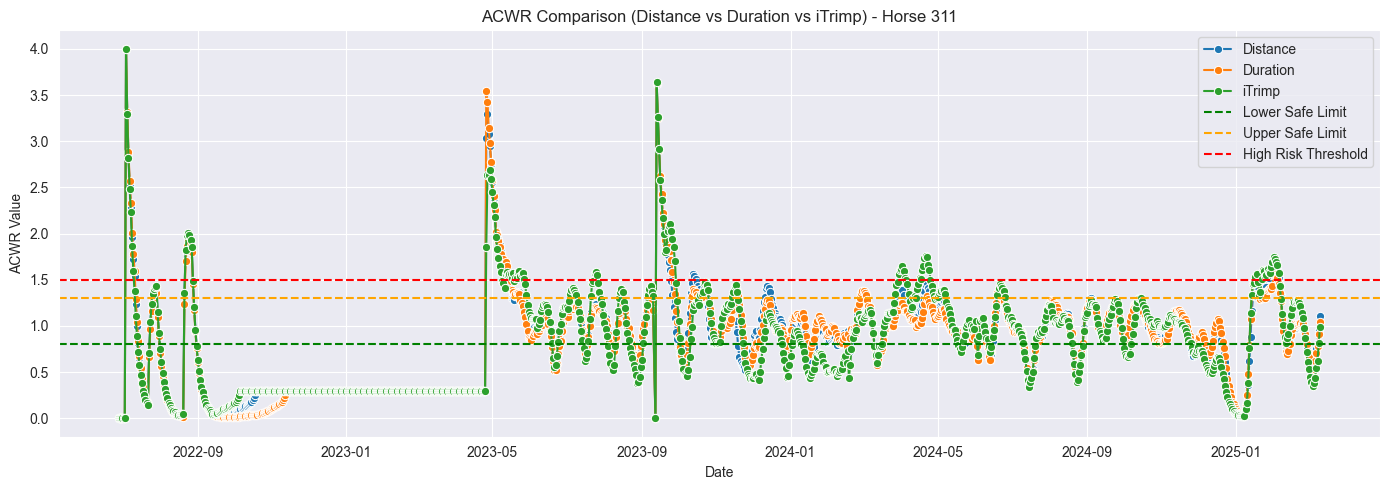

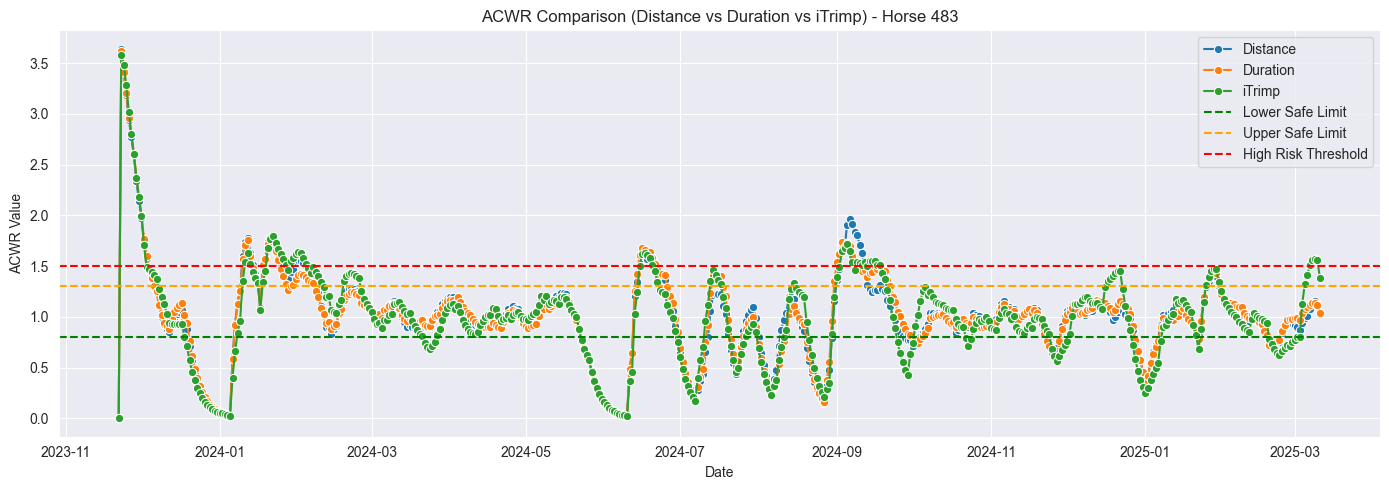

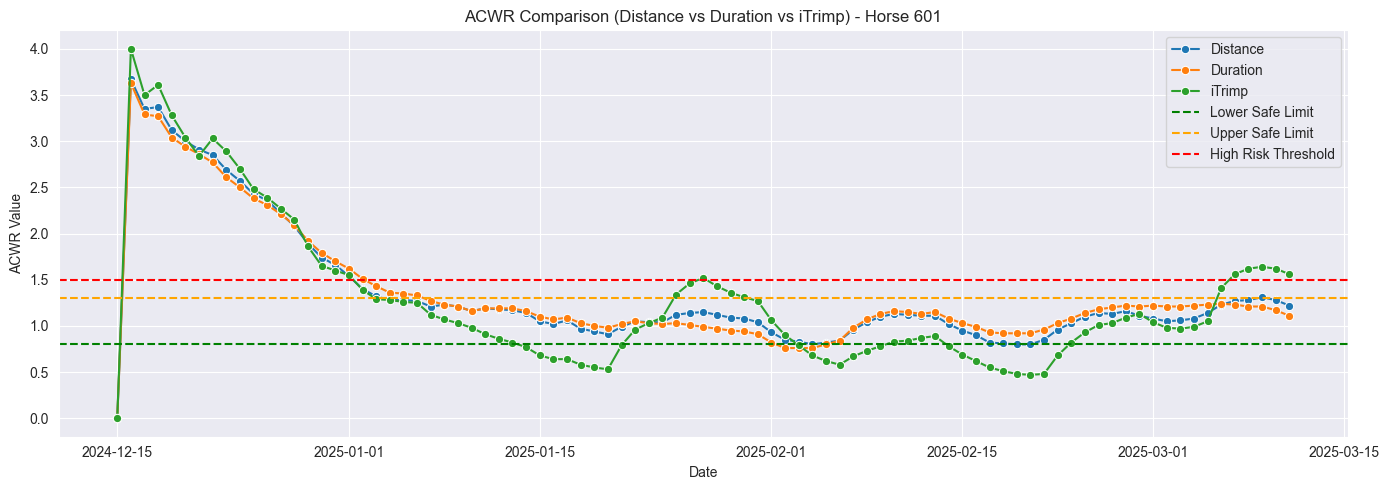

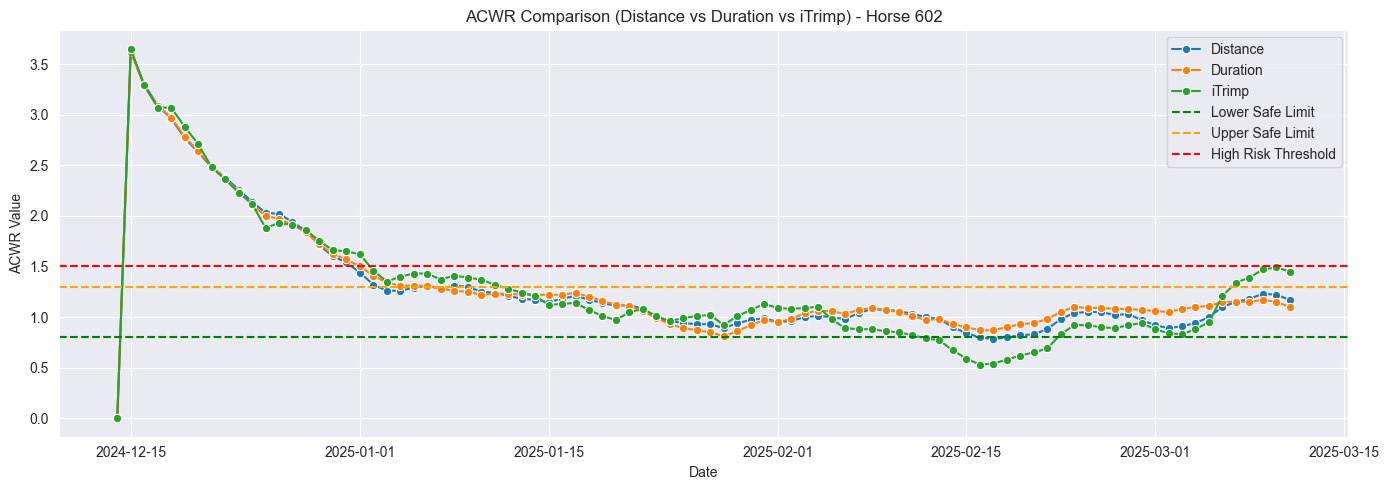

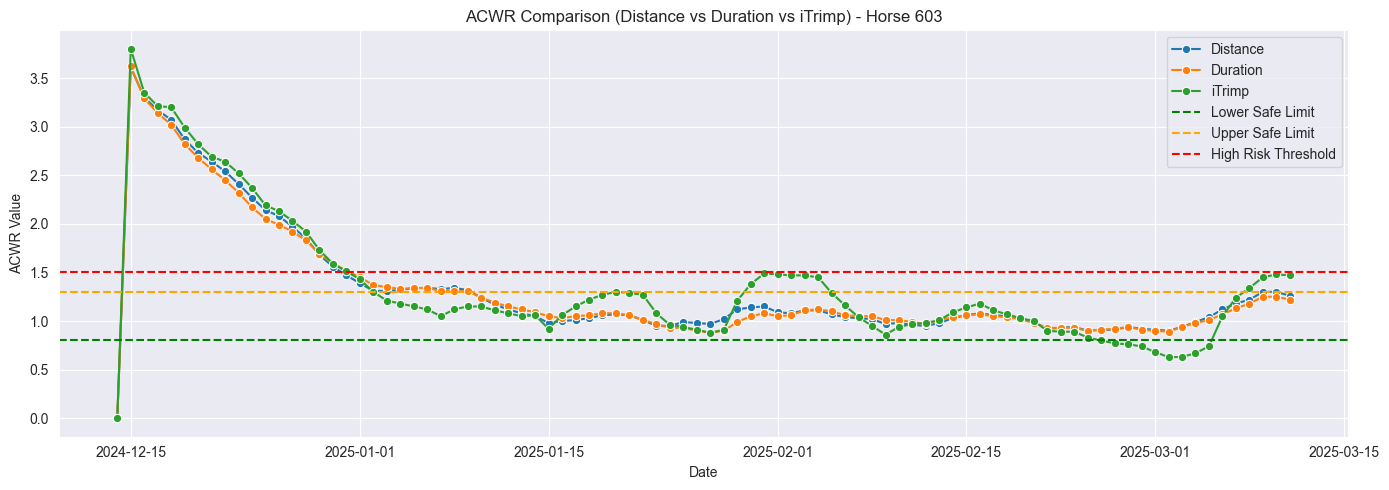

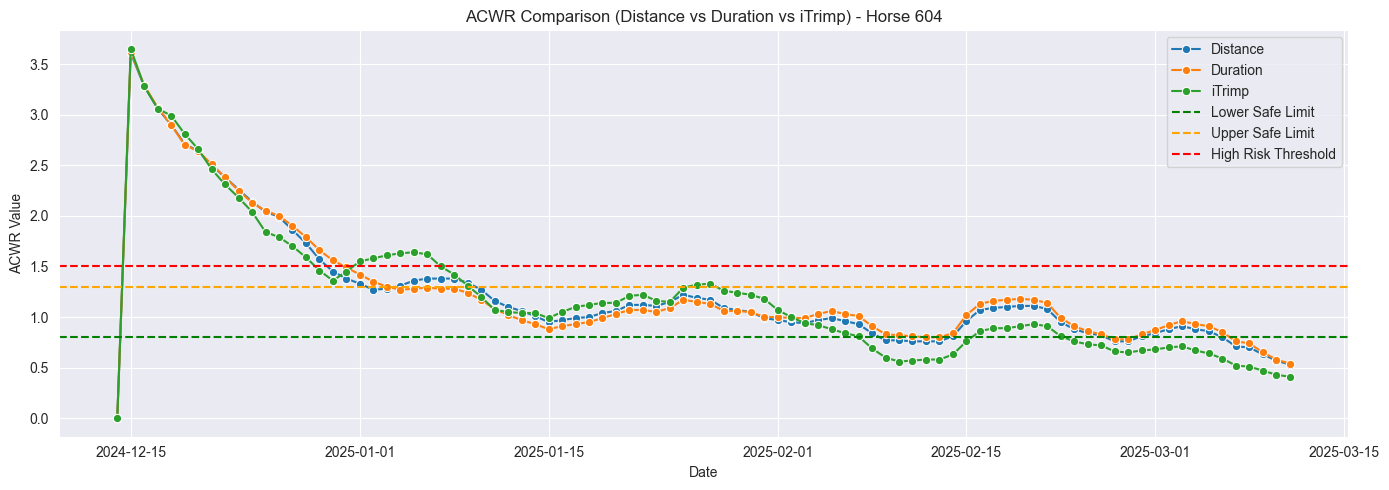

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the 3 ACWR metric columns
acwr_cols = {
    'Distance': 'externalDistance_Distance_ACWR',
    'Duration': 'externalDuration_Duration_ACWR',
    'iTrimp': 'iTrimp_overall_ACWR'
}

# Prepare data: keep only relevant columns
acwr_df = df[['HorseID', 'Date'] + list(acwr_cols.values())].dropna()

# Convert to float
for col in acwr_cols.values():
    acwr_df[col] = acwr_df[col].astype(float)

# Melt to long format for seaborn
df_melted = acwr_df.melt(id_vars=['HorseID', 'Date'], 
                         value_vars=acwr_cols.values(), 
                         var_name='ACWR_Type', 
                         value_name='ACWR_Value')

# Optional: map technical column names to readable ones
df_melted['ACWR_Type'] = df_melted['ACWR_Type'].map({
    'externalDistance_Distance_ACWR': 'Distance',
    'externalDuration_Duration_ACWR': 'Duration',
    'iTrimp_overall_ACWR': 'iTrimp'
})

# Get unique horses
horses = df_melted['HorseID'].unique()

# Plot all three metrics for each horse
for horse_id in horses:
    horse_df = df_melted[df_melted['HorseID'] == horse_id]

    plt.figure(figsize=(14, 5))
    sns.lineplot(data=horse_df, x='Date', y='ACWR_Value', hue='ACWR_Type', marker='o')
    
    # Thresholds
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold')

    plt.title(f'ACWR Comparison (Distance vs Duration vs iTrimp) - Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Data cleaning
We are to drop the first 4 months for every horse, since they are not correct data

In [14]:
one_month_cutoff = df.groupby('HorseID')["Date"].transform(
    lambda s: s.min() + pd.DateOffset(months=1)   # earliest date + 1 month
)

df_clean = df[df["Date"] >= one_month_cutoff].copy()

df_clean

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
30,257,2022-12-04,7.02,38.37,35.25,30.47,1.16,1.00,9.72,9.80,...,6.37,15.06,10.45,9.57,1.09,0.0,0.0,0.00,0.00,0.00
31,257,2022-12-05,0.00,31.71,34.37,30.56,1.12,0.00,8.30,9.43,...,0.00,12.41,10.94,9.77,1.12,0.0,0.0,0.00,0.00,0.00
32,257,2022-12-06,8.88,38.04,35.29,31.08,1.14,6.03,14.33,10.66,...,0.73,13.14,11.49,10.00,1.15,0.0,0.0,0.00,0.00,0.00
33,257,2022-12-07,0.00,29.70,33.89,30.98,1.09,0.00,10.60,10.65,...,0.00,12.28,11.69,10.16,1.15,0.0,0.0,0.00,0.00,0.00
34,257,2022-12-08,0.00,21.57,30.81,30.33,1.02,0.00,9.00,10.24,...,0.00,8.27,10.84,10.03,1.08,0.0,0.0,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2667,604,2025-03-07,0.00,5.89,12.82,18.06,0.71,0.00,1.57,3.63,...,0.00,0.47,1.72,2.94,0.59,0.0,0.0,0.67,9.03,0.07
2668,604,2025-03-08,4.81,10.69,12.29,17.55,0.70,0.80,2.37,3.32,...,0.45,0.91,1.52,2.80,0.54,0.0,0.0,0.50,8.41,0.06
2669,604,2025-03-09,0.00,4.81,10.42,16.67,0.63,0.00,0.80,2.69,...,0.00,0.45,1.25,2.64,0.47,0.0,0.0,0.38,7.83,0.05
2670,604,2025-03-10,0.00,4.81,9.02,15.85,0.57,0.00,0.80,2.22,...,0.00,0.45,1.05,2.49,0.42,0.0,0.0,0.29,7.29,0.04


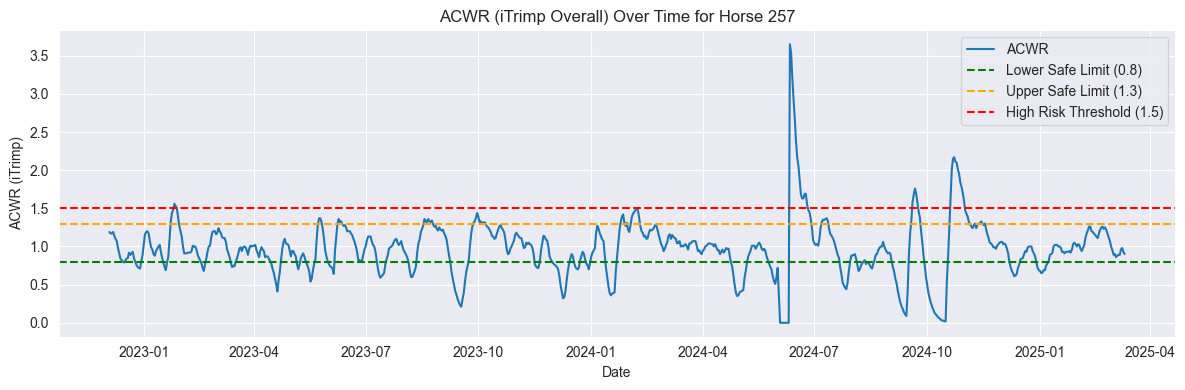

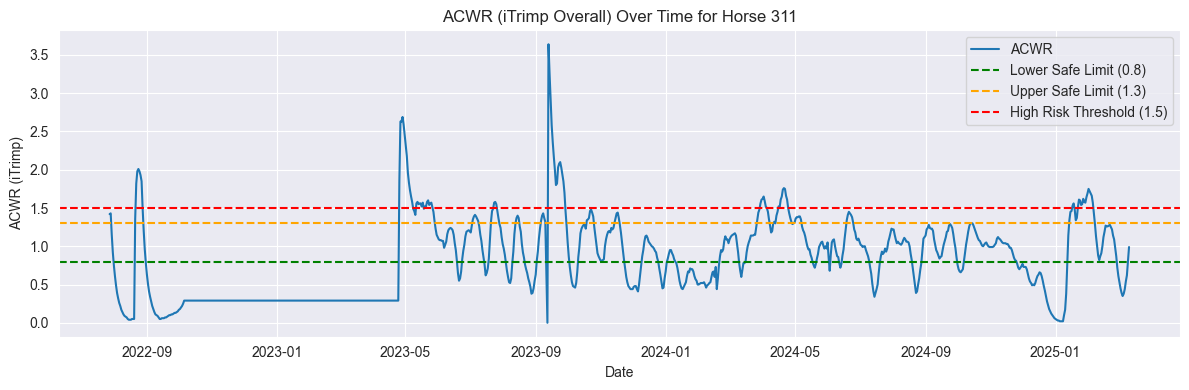

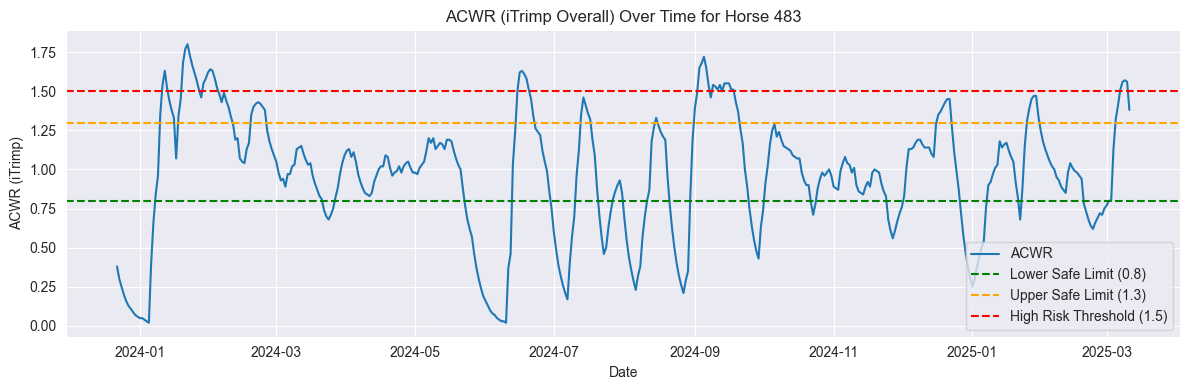

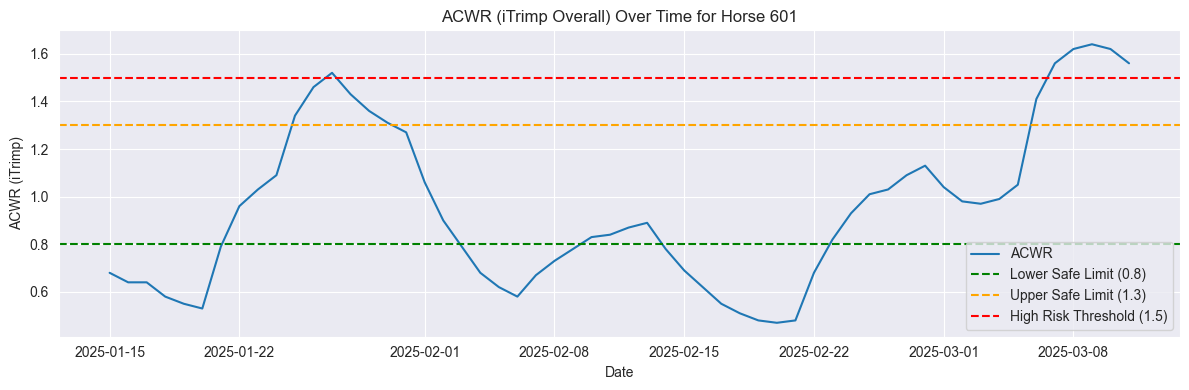

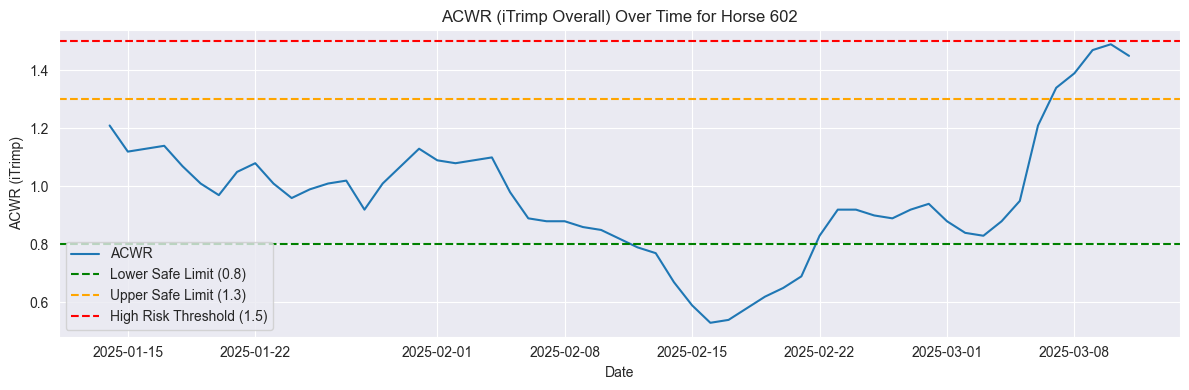

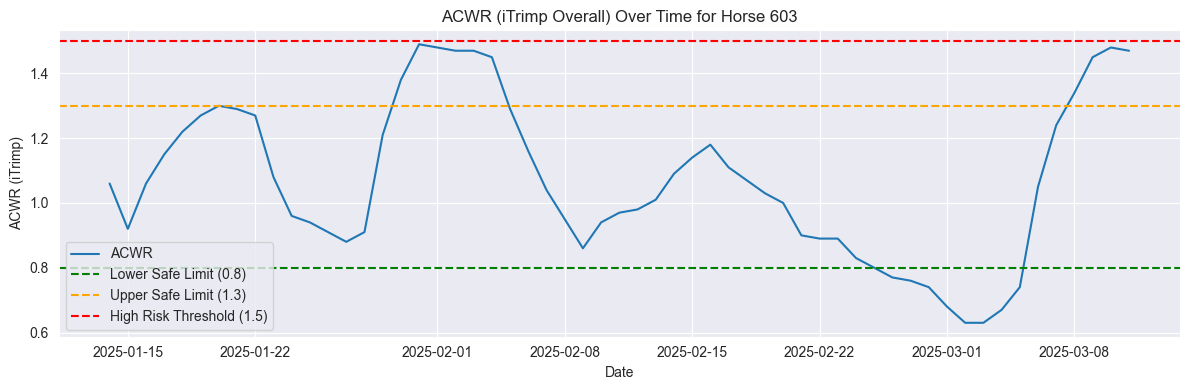

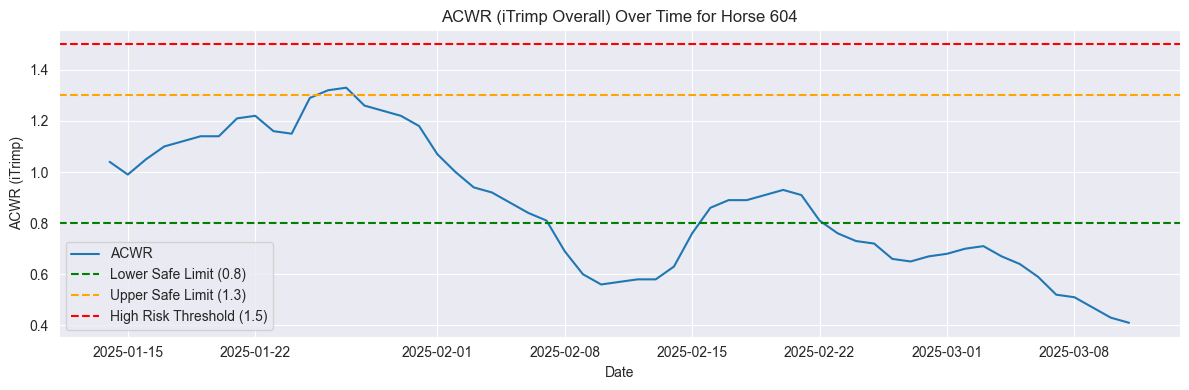

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ACWR metric for internal training load
acwr_col = 'iTrimp_overall_ACWR'

# Filter and clean
df_acwr = df_clean[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: tag risk levels
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # ACWR safe zone lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (iTrimp Overall) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (iTrimp)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Predicting ACWR Using Random Forest Regression

In this section, a Random Forest Regressor is used to predict the Acute Chronic Workload Ratio (ACWR) for a selected horse based on historical ACWR values. The workflow includes:

- Selecting a single horse (257) and preparing its ACWR from ITrimp. (since 257 horse has longest documentations that is why I chose it to work with first)
- Creating lag features and rolling averages to capture recent trends.
- Splitting the data into training and test sets.
- Training a Random Forest model to predict future ACWR values.
- Evaluating model performance and visualizing predictions.


In [16]:
horse_id = "257"  # choose one horse
df_horse = df_clean[df_clean["HorseID"] == horse_id].copy()

# Select relevant columns
acwr_col = "externalDistance_Distance_ACWR"
df_horse = df_horse[["Date", acwr_col]].dropna()
df_horse[acwr_col] = df_horse[acwr_col].astype(float)
\
df_horse


,Date,externalDistance_Distance_ACWR
30,2022-12-04,1.16
31,2022-12-05,1.12
32,2022-12-06,1.14
33,2022-12-07,1.09
34,2022-12-08,1.02
...,...,...
853,2025-03-07,0.85
854,2025-03-08,0.92
855,2025-03-09,0.94
856,2025-03-10,0.91


### Check for missing values and data type

In [17]:
# Check for missing values
print("\nMissing Values:")
print(df_horse.isnull().sum())

print("\nData types of df:")
print(df_horse.dtypes)



Missing Values:
Date                              0
externalDistance_Distance_ACWR    0
dtype: int64

Data types of df:
Date                              datetime64[ns]
externalDistance_Distance_ACWR           float64
dtype: object


### Create lags from previous 7 days

In [18]:
# Sort by date
df_horse.sort_values("Date", inplace=True)

# Create lag features (past 1 to 7 days)
for lag in range(1, 8):
    df_horse[f"lag_{lag}"] = df_horse[acwr_col].shift(lag)

# Rolling averages
df_horse["rolling_mean_3"] = df_horse[acwr_col].shift(1).rolling(3).mean()
df_horse["rolling_mean_7"] = df_horse[acwr_col].shift(1).rolling(7).mean()

df_horse


,Date,externalDistance_Distance_ACWR,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,rolling_mean_3,rolling_mean_7
30,2022-12-04,1.16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31,2022-12-05,1.12,1.16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,2022-12-06,1.14,1.12,1.16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33,2022-12-07,1.09,1.14,1.12,1.16,NaN,NaN,NaN,NaN,1.140000,NaN
34,2022-12-08,1.02,1.09,1.14,1.12,1.16,NaN,NaN,NaN,1.116667,NaN
...,...,...,...,...,...,...,...,...,...,...,...
853,2025-03-07,0.85,0.85,0.86,0.85,0.91,0.94,0.99,1.03,0.853333,0.918571
854,2025-03-08,0.92,0.85,0.85,0.86,0.85,0.91,0.94,0.99,0.853333,0.892857
855,2025-03-09,0.94,0.92,0.85,0.85,0.86,0.85,0.91,0.94,0.873333,0.882857
856,2025-03-10,0.91,0.94,0.92,0.85,0.85,0.86,0.85,0.91,0.903333,0.882857


### Train/ Split

In [19]:
from sklearn.model_selection import train_test_split

X = df_horse.drop(columns=["Date", acwr_col])
y = df_horse[acwr_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.2)


In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, max_error

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
max_error = max_error(y_test, y_pred)

print(f"Test MSE: {mse:.4f}")
print(f"Test RMSE: {mse**0.5:.4f}")
print(f"Max_Error: {max_error:.4f}")
print(f"R² Score: {r2:.4f}")


Test MSE: 0.0180
Test RMSE: 0.1343
Max_Error: 0.9710
R² Score: 0.8797


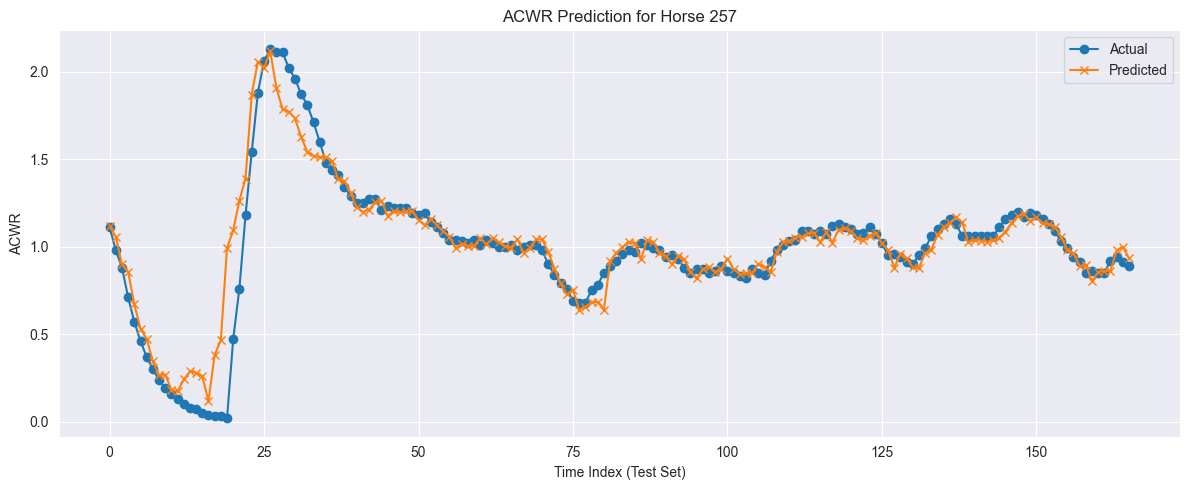

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values, label="Actual", marker='o')
plt.plot(y_pred, label="Predicted", marker='x')
plt.title(f"ACWR Prediction for Horse {horse_id}")
plt.xlabel("Time Index (Test Set)")
plt.ylabel("ACWR")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Check for errors

In [22]:
predictions = model.predict(X_test)
prediction_overview = pd.DataFrame()
prediction_overview["Actual"] = y_test
prediction_overview["Predicted"] = predictions
prediction_overview["Error"] = abs(prediction_overview["Actual"] - prediction_overview["Predicted"]).round(2)
prediction_overview.reset_index(drop=True, inplace=True)
prediction_overview.head(10).sort_values("Error", ascending=False)


,Actual,Predicted,Error
3,0.71,0.8556,0.15
4,0.57,0.6697,0.10
6,0.37,0.4738,0.10
1,0.98,1.0562,0.08
9,0.19,0.2693,0.08
5,0.46,0.5311,0.07
7,0.30,0.3446,0.04
8,0.24,0.2668,0.03
2,0.88,0.8983,0.02
0,1.11,1.1174,0.01


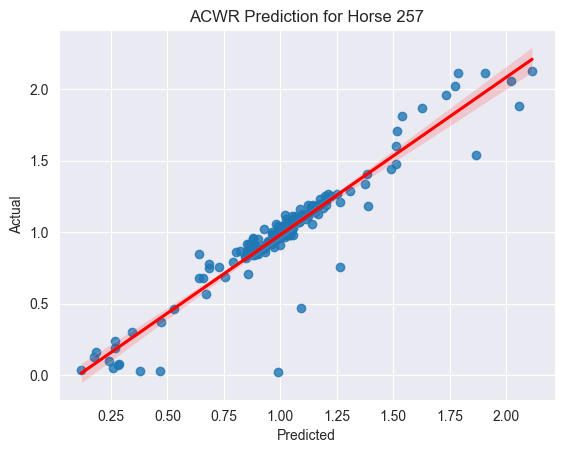

In [23]:
plot = sns.regplot(y=y_test.values.flatten(), x=predictions.flatten(), line_kws={"color": "red"})
plot.set_title(f"ACWR Prediction for Horse {horse_id}")
plot.set(xlabel="Predicted", ylabel="Actual")
plt.show()

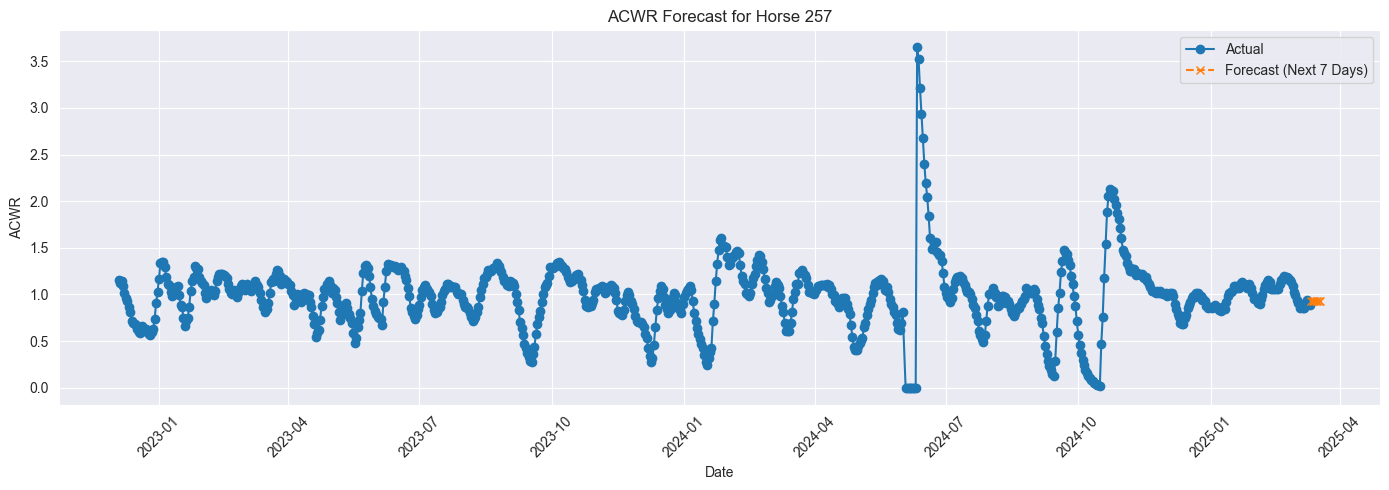

In [24]:
from datetime import timedelta
import matplotlib.pyplot as plt
import pandas as pd

# Get the latest input features
latest_input = df_horse.iloc[-1:].drop(columns=["Date", acwr_col])

# Predict for next 7 days (reusing the same input for simplicity)
X_future = pd.concat([latest_input] * 7, ignore_index=True)
future_preds = model.predict(X_future)

# Build future date index
last_date = df_horse["Date"].iloc[-1]
future_dates = [last_date + timedelta(days=i) for i in range(1, 8)]

# Plot actual + predicted
plt.figure(figsize=(14, 5))
plt.plot(df_horse["Date"], df_horse[acwr_col], label="Actual", marker='o')
plt.plot(future_dates, future_preds, label="Forecast (Next 7 Days)", marker='x', linestyle='--')

plt.title(f"ACWR Forecast for Horse {horse_id}")
plt.xlabel("Date")
plt.ylabel("ACWR")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


### Evaluation and Suitability of the Random Forest Approach

The Random Forest model provides a straightforward way to predict future ACWR values using lagged features and rolling averages. While the model can capture some short-term trends and non-linear relationships, there are important limitations to consider:

- **Time Series Structure Ignored:** Random Forest does not explicitly model temporal dependencies or seasonality, which are often present in workload data. It treats each row as independent, potentially missing important sequential patterns.
- **Feature Reuse for Forecasting:** The forecast for the next 7 days reuses the same input features, assuming the horse's activity pattern remains unchanged. This is unrealistic and can lead to misleading predictions, especially for longer horizons.
- **Data Size and Overfitting:** With limited data for a single horse, the model may overfit to noise or fail to generalize to new patterns.
- **No Uncertainty Estimates:** Random Forest does not provide confidence intervals or uncertainty estimates for its predictions, which are valuable in risk management.

**Conclusion:**
After reviewing with this model I realized that predicting future with this model might be pretty invalid. Also for scope of this project I felt like this wont help us to move anyway so I decided to not to engage with this model and rather tried to find different solution for our problem.

## Generating Feedback with the Ollama Model

In this section, a large language model (LLM) is used to generate professional feedback for horse trainers based on recent ACWR (Acute:Chronic Workload Ratio) summaries. The approach involves:

- Summarizing the latest ACWR metrics and trends for a selected horse.
- Sending this summary as a prompt to the Ollama model (using the Mistral LLM) via a local command-line interface.
- Automatically generating a concise, expert-level feedback message tailored to the horse's recent workload and risk profile.


In [25]:
import subprocess
import json

def generate_local_feedback(summary_text):
    prompt = f"""
    You are an equine horse sports scientist. Based on the following summary of horse training data, generate a short and professional feedback message for the trainer of the horse.

    Summary:
    {summary_text}

    Feedback:
    """
    
    # Send to Ollama (CLI mode)
    result = subprocess.run(
        ['ollama', 'run', 'mistral'],
        input=prompt.encode(),
        stdout=subprocess.PIPE
    )

    output = result.stdout.decode('utf-8')
    return output.strip()


Keep in mind that model might take time till its generate response. With this data for me it took 30-40 seconds but that would depend on a PC as well. That is why more data might naturally increase the time till the model will generate its response.

In [27]:
# # input the horse 257 ITrimp data
last_7 = df_horse[acwr_col].iloc[-7:]
current_acwr = last_7.iloc[-1]
weekly_avg = last_7.mean()
trend = "increasing" if last_7.diff().mean() > 0 else "decreasing"

summary = f"""
- Current ACWR: {current_acwr:.2f}
- Weekly average: {weekly_avg:.2f}
- Trend: {trend}
- Risk Zone: {"Overtraining" if current_acwr > 1.5 else "Optimal" if current_acwr <= 1.3 else "Undertraining"}
- Last 7 ACWR: {', '.join([f'{v:.2f}' for v in last_7])}
"""

feedback = generate_local_feedback(summary)
print(feedback)


Dear Trainer,

   I hope this message finds you well. I am writing to provide an update on the performance analysis of your horse based on the past week's data.

   The Average Coordination, Willingness, and Response (ACWR) score for the last week has remained consistently high, averaging 0.89. This is commendable as it indicates a strong partnership between you and the horse during training sessions.

   It is encouraging to see that the trend shows an increase in ACWR scores over the past weeks. The current score places your horse in the Optimal Risk Zone, which is a positive sign of their mental and physical readiness for further training.

   In particular, I would like to highlight the improvement observed in recent sessions. While we did see slight dips during the middle of the week, the overall progress has been steady and promising.

   Continue to maintain the current pace and focus on reinforcing positive responses from your horse as they have shown a clear willingness to lea

In [61]:
last_7 = df_horse[acwr_col].iloc[-7:]
current_acwr = last_7.iloc[-1]
weekly_avg = last_7.mean()
trend = "increasing" if last_7.diff().mean() > 0 else "decreasing"

import subprocess

def build_acwr_prompt(acwr_series):
    last_7 = acwr_series.iloc[-7:]
    current_acwr = last_7.iloc[-1]
    weekly_avg = last_7.mean()
    trend = "increasing" if last_7.diff().mean() > 0 else "decreasing"
    if current_acwr > 1.5:
        risk_zone = "Overtraining"
        rationale = "The current acute:chronic workload ratio is above 1.5, indicating a significant workload spike."
    elif weekly_avg < 1.05:
        risk_zone = "Low Training Load"
        rationale = f"The weekly average ratio of {weekly_avg:.2f} is below 1.05, suggesting a slight increase is needed."
    elif current_acwr <= 1.3:
        risk_zone = "Optimal"
        rationale = "The ratio is within the optimal range (<= 1.3), indicating balanced workload."
    else:
        risk_zone = "Undertraining"
        rationale = "The ratio is between 1.3 and 1.5, indicating the horse may need more challenge."
    context = "Acute:Chronic Workload Ratio (ACWR) measures recent workload versus longer-term load. Ratios above 1.5 signal overtraining risk; 1.3–1.5 may indicate undertraining; at or below 1.3 is optimal."
    return f"""
You are an expert equine performance coach. {context}

Here are the ACWR details for the horse over the last 7 days:
- Last 7 ACWR values: {', '.join([f"{v:.2f}" for v in last_7])}
- Current ACWR: {current_acwr:.2f}
- Weekly average ACWR: {weekly_avg:.2f}
- Trend: {trend}
- Risk Zone: {risk_zone}
- Rationale: {rationale}

Based on this information, provide specific, actionable advice on how to adjust the horse's training plan, including suggestions for modifying workload, recovery strategies, and how to monitor progress.
"""

prompt = build_acwr_prompt(df_horse[acwr_col])

proc = subprocess.run(
    ["ollama", "run", "gemma"],
    input=prompt.encode("utf-8"),
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

# Decode with errors='replace' so you don’t get Unicode errors
out = proc.stdout.decode("utf-8",    errors="replace")
err = proc.stderr.decode("utf-8",    errors="replace")

if proc.returncode != 0:
    print("Ollama error:", err)
else:
    print(out)


## Specific, actionable advice for training plan adjustments:

**Workload Modification:**

* **Increase training volume gradually:** 5-10% per week until reaching a comfortable working level. 
* **Target specific training sessions:** Prioritize light-intensity gallops or trotting exercises for additional workload.
* **Consider frequency of training:** Maintain current frequency of workouts or slightly increase to 2-3 additional sessions per week.

**Recovery Strategies:**

* **Implement active recovery days:** Include 1-2 days per week where the horse engages in light exercise like walking or hand-grazing.
* **Increase stall/pasture time:** Ensure access to ample space and enrichment to support mental and physical recovery.
* **Adequate sleep:** Promote adequate nighttime rest (12-14 hours) for optimal performance and recovery.

**Monitoring Progress:**

* **Continue tracking ACWR:** Monitor daily values to assess workload impact and adjust training accordingly.
* **Record training int

In [63]:
# Combined Cell: Generate ACWR feedback and format it into a collaborative email

import subprocess

# Calculate ACWR metrics
last_7 = df_horse[acwr_col].iloc[-7:]
current_acwr = last_7.iloc[-1]
weekly_avg = last_7.mean()
trend = "increasing" if last_7.diff().mean() > 0 else "decreasing"

# Build the prompt
def build_acwr_prompt(acwr_series):
    last_7 = acwr_series.iloc[-7:]
    current_acwr = last_7.iloc[-1]
    weekly_avg = last_7.mean()
    trend = "increasing" if last_7.diff().mean() > 0 else "decreasing"
    if current_acwr > 1.5:
        risk_zone = "Overtraining"
        rationale = "The current acute:chronic workload ratio is above 1.5, indicating a significant workload spike."
    elif weekly_avg < 1.05:
        risk_zone = "Low Training Load"
        rationale = f"The weekly average ratio of {weekly_avg:.2f} is below 1.05, suggesting a slight increase is needed."
    elif current_acwr <= 1.3:
        risk_zone = "Optimal"
        rationale = "The ratio is within the optimal range (<= 1.3), indicating balanced workload."
    else:
        risk_zone = "Undertraining"
        rationale = "The ratio is between 1.3 and 1.5, indicating the horse may need more challenge."
    context = (
        "Acute:Chronic Workload Ratio (ACWR) measures recent workload versus longer-term load. "
        "Ratios above 1.5 signal overtraining risk; 1.3–1.5 may indicate undertraining; at or below 1.3 is optimal."
    )
    return f"""
You are an expert equine performance coach. {context}

Here are the ACWR details for the horse over the last 7 days:
- Last 7 ACWR values: {', '.join([f"{v:.2f}" for v in last_7])}
- Current ACWR: {current_acwr:.2f}
- Weekly average ACWR: {weekly_avg:.2f}
- Trend: {trend}
- Risk Zone: {risk_zone}
- Rationale: {rationale}

Based on this information, provide specific, actionable advice on how to adjust the horse's training plan,
including suggestions for modifying workload, recovery strategies, and how to monitor progress.
"""

# Generate feedback via Ollama
prompt = build_acwr_prompt(df_horse[acwr_col])
proc = subprocess.run(
    ["ollama", "run", "gemma"],
    input=prompt.encode("utf-8"),
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

# Decode output safely
feedback = proc.stdout.decode("utf-8", errors="replace") if proc.returncode == 0 else f"Error: {proc.stderr.decode('utf-8', errors='replace')}"

# Build the email
trainer_name = "Trainer"
horse_id = "257"
email_body = f"""Subject: Collaborative Training Plan for Horse {horse_id}
From: EI Team <ei-team@example.com>
To: {trainer_name} <trainer@example.com>

Hi {trainer_name},

I hope you and Horse {horse_id} are doing well. We’ve reviewed the latest ACWR data and have outlined some steps we can take together:

{feedback}

Please let us know your thoughts or if you’d like to adjust anything. We’re here to support you and {trainer_name} every step of the way.

Warm regards,

EI Team
"""

# Print the email
print(email_body)


Subject: Collaborative Training Plan for Horse 257
From: EI Team <ei-team@example.com>
To: Trainer <trainer@example.com>

Hi Trainer,

I hope you and Horse 257 are doing well. We’ve reviewed the latest ACWR data and have outlined some steps we can take together:

## Training Plan Adjustments:

**1. Workload Modification:**

* Gradually increase the intensity or duration of training sessions over the next week.
* Implement varied workload intervals within each session.
* Consider incorporating short recovery gallops or walk intervals into training.
* Maintain consistent warm-up and cool-down routines.


**2. Recovery Strategies:**

* Ensure adequate rest between training sessions.
* Implement cooling down strategies after each workout with 5-10 minutes of walk/trot.
* Provide access to cool water and salt after exercise.
* Implement a regular massage or stretching routine.


**3. Monitoring Progress:**

* Continue tracking and recording ACWR values daily.
* Monitor other performance ind

In [66]:
# Instruct Gemma to remove '*' and markdown, and soften the tone
rewrite_prompt = (
    "Please rewrite the following email so that it is plain text (no '*' or '**' or markdown), "
    "a bit more conversational, and friendly:\n\n"
    + email_body
)

proc3 = subprocess.run(
    ["ollama", "run", "gemma"],
    input=rewrite_prompt.encode("utf-8"),
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

if proc3.returncode == 0:
    human_email = proc3.stdout.decode("utf-8", errors="replace")
else:
    human_email = f"Error rewriting email: {proc3.stderr.decode('utf-8', errors='replace')}"

print(human_email)


## Subject: Horse 257 Training Plan Review

Hi Trainer,

Hope you and Horse 257 are doing great!

We've reviewed the latest ACWR data and put together some adjustments to the training plan to maximize your horse's performance.

**Here's what we're thinking:**

**1. Training intensity:** We can gradually increase the intensity of your training sessions over the next week, but let's mix it up a bit. We can also incorporate short rest periods or walks into the mix. Remember to stick with those warm-up and cool-down routines!

**2. Recovery is key:** Ensuring your horse gets adequate rest between sessions is crucial. We also need to cool down after each workout with a 5-10 minute walk/trot period. Providing cool water and salt after exercise is important too, and consider regular massages or stretches.

**3. Monitoring progress:** Keep tracking those ACWR values daily, but let's not stop there. We also need to monitor heart rate, respiratory rate, manure consistency, attitude, energy level

In [69]:
import subprocess

# 0. Point these at your actual column names
date_col  = "Date"   # e.g. "Date"
load_col  = "Load"   # e.g. "Training Load"
acwr_col  = "ACWR"   # e.g. "ACWR"
zone_col  = "Zone"   # e.g. "Zone"

# 1. Build a textual summary for the last 7 days
last7 = df_horse.tail(7)
summary_lines = last7.apply(
    lambda r: (
        f"{r[date_col].strftime('%d %B')}: "
        f"Load={r[load_col]}, "
        f"ACWR={r[acwr_col]:.2f}, "
        f"Zone={r[zone_col]}"
    ),
    axis=1
)
summary_text = "\n".join(summary_lines)

# 2. Feedback generator (Dutch, with example style)
def generate_local_feedback(summary_text):
    prompt = f"""
You are an equine sports scientist. Based on the horse's training data, write a short and helpful feedback message for the trainer. I'm going to give you:
 - An example message, which you should analyze and keep the same writing style and structure
 - Horse Summary Data
 - Data explanation
 - Guidelines on what you should give back as answer

Example message:
hierbij de feedback op de laatste trainingen:
18 juni: Galop is nog wat intensiever, maar hij herstelt hier wel redelijk van. Laatste draf blok is wel matig tot hoog intensieve draf werk voor hem. Niet erg voor een keer, maar beter om dit blok op te delen in 2 of 3 kortere blokjes afgewisseld met wat stap.
21 juni: wel intensief dagje, blokjes in de galop zijn wel van hoge intensiteit maar niet meteen verkeerd en ook niet alleen inspanning want herstel erna is redelijk snel en te snel als het alleen maar hoog was van inspanning. Goed dat je korte stukjes hebt gedaan. Stukje proef op einde wel goed, was ook iets hoger intensief, maar dat mag, hij mag er ook aan blijven trekken zeg maar. herstel na de training was snel en goed dus al met al matig intensieve training. Dus denk goede intensiteit en technisch ook goed.
22 juni: prima herstel dagje in het bos.
--- Example message End ---

Horse Summary Data:
{summary_text}
--- Training Summary End ---

Data Explanation:
- Date
- Training Load (Load)
- ACWR (Acute:Chronic Workload Ratio)
- Zone (training quality: undertrained, optimal, overtrained)
--- Data Explanation End ---

Guidelines:
- Comment on the overall training balance.
- Point out gaits that are undertrained or overtrained (based on Zone).
- Note that some days have Load = 0 (recovery days).
- Give clear advice on adjusting training or giving rest.
- Write the message in Dutch.
- DO NOT include "---feedback end---" at the end of the message.
- Follow the structure date: feedback.

Provide only the feedback with explanations. No summaries.
"""
    result = subprocess.run(
        ["ollama", "run", "mistral"],
        input=prompt.encode("utf-8"),
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr.decode("utf-8"))
    return result.stdout.decode("utf-8").strip()

# 3. Generate the feedback
feedback = generate_local_feedback(summary_text)

# 4. Build the collaborative email
trainer_name = "Trainer"
horse_id      = "257"
email_body = f"""Subject: Collaborative Training Plan for Horse {horse_id}
From: EI Team <ei-team@example.com>
To: {trainer_name} <trainer@example.com>

Hi {trainer_name},

Ik hoop dat alles goed gaat met jou en Paard {horse_id}. Hieronder vind je de feedback op de meest recente trainingen:

{feedback}

Laat gerust weten wat je ervan vindt of als je iets wilt aanpassen. We staan klaar om je te ondersteunen.

Met vriendelijke groet,

EI Team
"""

# 5. Print (or send) the email
print(email_body)


KeyError: 'Load'